# Längenkontrollierte Analyse der QA-basierten Faktenretention

## Eingaben und Ausgaben

Nach der einmaligen Vorbereitung mit `python 05_analyze.py --prepare` genügt **Run All**.
Die folgende Zelle zeigt Daten, Vorgängertabellen und neue Ausgaben. `DATA_DIR` und
`OUTPUT_DIR` dürfen auf eigene absolute Verzeichnisse zeigen. `TABLES` liest standardmäßig
die vorbereiteten historischen Tabellen; für selbst neu erzeugte Vorgängertabellen
kann hier `OUTPUT_DIR / "tables"` stehen. Eingaben und neue Ausgaben bleiben getrennt.


In [1]:
from pathlib import Path
from faktenretention.paths import PROJECT_ROOT
from faktenretention.notebook_context import setup_notebook
from faktenretention.io import relative_path, sha

# Hier können eigene absolute Daten- und Ausgabeverzeichnisse stehen.
DATA_DIR = PROJECT_ROOT / "data/prepared"
OUTPUT_DIR = PROJECT_ROOT / "results/notebooks"
# Historische Vorgängertabellen; für eigene Neuberechnungen OUTPUT_DIR / "tables" einsetzen.
TABLES = DATA_DIR / "tables"
setup_notebook(DATA_DIR, OUTPUT_DIR)
OUT = OUTPUT_DIR / "tables/11_statistische_laengenkontrolle"
FIG = OUTPUT_DIR / "figures/11_statistische_laengenkontrolle"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Eingaben:", DATA_DIR / "qa")
print("Vorgängertabellen:", TABLES)
print("Regressionscaches:", DATA_DIR / "caches/11_statistische_laengenkontrolle")
print("Neue Tabellen:", OUT)
print("Neue Grafiken:", FIG)
from faktenretention.runtime_checks import check_analysis_environment
check_analysis_environment(strict_cache=True)


Eingaben: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/qa
Vorgängertabellen: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/tables
Regressionscaches: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/caches/11_statistische_laengenkontrolle
Neue Tabellen: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/tables/11_statistische_laengenkontrolle
Neue Grafiken: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/figures/11_statistische_laengenkontrolle


{'platform': 'Linux',
 'cache_compatible': True,
 'versions': {'python': '3.13.15',
  'numpy': '2.5.4',
  'pandas': '3.0.6',
  'scipy': '1.18.1',
  'statsmodels': '0.15.0',
  'patsy': '1.0.3',
  'matplotlib': '3.11.2',
  'scikit-learn': '1.9.1',
  'seaborn': '0.13.2',
  'rouge-score': '0.1.2',
  'nltk': '3.9.4',
  'ipython': '9.17.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0',
  'nbconvert': '7.17.2',
  'ipykernel': '7.4.0'}}

## 1. Zielsetzung und Methodik

Bleiben die beobachteten Unterschiede zwischen Prompting-Verfahren bei **vergleichbarer
tatsächlicher Wortzahl** bestehen? Untersucht werden ausschließlich die finalen
Hauptexperimentdaten: 100 Artikel, sechs Verfahren, vier Zielstufen, 2.400 Ausgaben und
48.000 QA-Positionen. Die primäre Regression umfasst die fünf generativen Verfahren.
Lead-k bleibt eine separate deterministische Präfixreferenz.

**Umfang:** neues Notebook und neues Ausgabeverzeichnis. Keine neuen LLM-Aufrufe,
keine neuen menschlichen Urteile, keine Neuklassifikation, keine Änderung von Texten,
Originaldaten, Scorer, vorhandenen Notebooks oder Ergebnissen. Das Notebook führt
statistische Modelle auf unverändert gespeicherten QA-Zählwerten aus.

Die Wortlänge ist selbst ein Ergebnis der Methode. Längenkontrolle liefert deshalb
**explorative bedingte Zusammenhänge**, keinen kausalen Methodeneffekt. Fehlende
empirische Überlappung wird nicht durch Regressionsvorhersagen ersetzt.

### Vorab offengelegte Analyseentscheidungen

- Hauptmodell: binomiales GLM mit Methode × Stufe, stufenspezifischem linearem
  Wortlängeneffekt und festen Artikeleffekten; clusterrobuste Kovarianz nach Artikel.
- Modellsensitivität: natürlicher kubischer Spline mit drei zentrierten Basisfunktionen
  je Stufe. Keine ergebnisabhängige Modellauswahl zugunsten eines Verfahrens.
- Primäre Vergleichsbereiche: Überschneidung der 5.–95.-Perzentilbereiche; zusätzlich
  mindestens 20 Beobachtungen je Verfahren und 20 gepaarte unterstützende Artikel.
  Eine lokale Nachbarschaftsprüfung verhindert Vergleiche allein aufgrund großer
  Min–Max-Hüllen. 20 ist eine transparente Analyseschwelle, keine Garantie ausreichender Präzision.
- Breitere Min–Max-Bereiche und engere 10.–90.-Perzentilbereiche dienen der Sensitivität.
- Standardisierung auf dieselben empirischen Wortzahlen **derselben Artikel** innerhalb
  des jeweiligen gestützten Paarbereichs, bei gleichgewichteten Artikeln.
- 95-%-Intervalle der standardisierten Differenzen: **10.000 vollständige
  Artikel-Cluster-Bootstrap-Modellanpassungen je Modell**, Seed 32; die Auswahlgrenzen
  bleiben in den Ziehungen fixiert. Lineare und flexible Modelle nutzen dieselben Ziehungen.

Python 3.13, NumPy, pandas, SciPy, Statsmodels, Patsy, Matplotlib und Jupyter.
Die Eingaben liegen relativ zu diesem Paket unter `DATA_DIR/qa/`, die
Ausgaben unter `OUTPUT_DIR/tables/11_statistische_laengenkontrolle/`. Die gespeicherten
Regressions-Bootstrap-Anpassungen werden ausschließlich aus fingerprintgeprüften
Caches gelesen.
Es werden keine externen Datendienste benötigt.

## Einordnung dieses Notebooks

**Warum diese Analyse?** Gleiche Zielwortzahlen führen in den tatsächlichen Ausgaben nicht zwingend zu gleichen Textlängen. Größere Retention kann deshalb zusammen mit einer höheren verfügbaren Wortzahl auftreten. Ein Vergleich ausschließlich nach Zielstufe trennt diese Zusammenhänge nicht.

**Forschungsfrage:** Welche Methodenunterschiede lassen sich innerhalb gemeinsamer, ausreichend gestützter Wortlängenbereiche beschreiben? Ein lineares und ein flexibles binomiales Modell mit festen Artikeleffekten dienen der Standardisierung; fehlende Überlappung wird als nicht schätzbar ausgewiesen.

**Zusammenhang:** Dies ist eine andere Fragestellung als die heuristische Längenstrafe und als die hypothetischen Messfehlerszenarien in Notebook 10. Die tatsächliche Wortlänge ist selbst ein Methodenergebnis. Die Analyse begründet daher keine kausale, vollständig von Kompressionsgeschichte oder QA-Fehlern bereinigte Verfahrenswirkung. Notebook 12 liefert ausschließlich einen ergänzenden LLM-Rater-Vergleich.

**Mitgelieferte Grundlage:** Die erste Codezelle zeigt die vorbereiteten Eingaben. Historische Definitionen liegen bytegleich unter `DATA_DIR/sources/`; sie dienen als Herkunftsbelege und werden nicht als Analysecode ausgeführt. Neue Tabellen stehen unter `OUTPUT_DIR/tables/`, Grafiken unter `OUTPUT_DIR/figures/`.


In [2]:
from pathlib import Path
from fractions import Fraction
from collections import Counter, defaultdict
from itertools import combinations
import ast, gzip, hashlib, html, importlib.metadata, json, math, os, platform, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display, Markdown, HTML

sys.dont_write_bytecode = True
BUNDLE = DATA_DIR
PACKAGE = DATA_DIR
ROOT = OUT
DATA = DATA_DIR / "qa"
ORIGINAL = TABLES / "03_qa_retention"
LENGTH = TABLES / "04_laenge_und_adjustierte_retention"
FIG.mkdir(parents=True,exist_ok=True)
VERSION = 'aktuell_20260930'
from faktenretention.protocol import METHODS
from faktenretention.protocol import LABELS as NAMES
from faktenretention.protocol import STAGES
from faktenretention.protocol import CONTRASTS
KEY = ['article_id','method','stage_target_words','canonical_fact_id']
CELL = ['article_id','method','stage_target_words']
SEED, B = 32, 10_000
GENERATIVE = METHODS[1:]
MIN_SUPPORT = 20
pd.set_option('display.max_rows',28)
pd.set_option('display.max_columns',16)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':200,'font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False})
STAGE_COLORS = {500:'#0072B2',300:'#D55E00',150:'#009E73',75:'#CC79A7'}

def export(frame,name):
    frame.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')

def savefig(fig,name):
    for extension in ['png','svg','pdf']:
        fig.savefig(FIG/f'{name}.{extension}',bbox_inches='tight')
    plt.show()
    plt.close(fig)

def pct(n,d): return 100*n/d if d else np.nan
def de(x,digits=2): return f'{x:.{digits}f}'.replace('.',',') if pd.notna(x) else 'nicht bestimmbar'

def read(path,strings=False):
    frame = pd.read_csv(path,keep_default_na=False,**({'dtype':str} if strings else {}))
    for column in ['article_id','stage_target_words']:
        if column in frame: frame[column] = frame[column].astype(int)
    return frame

software = {'python':platform.python_version(),**{m:importlib.metadata.version(m)
            for m in ['numpy','pandas','scipy','statsmodels','patsy','matplotlib','nbformat','nbclient','nbconvert','ipykernel']}}
display(pd.Series(software,name='Version').to_frame())
import time, warnings, inspect, importlib
import scipy.linalg as la
from scipy.special import expit
from scipy.stats import t as student_t
import patsy
import statsmodels.api as sm
METHOD_COLORS = dict(zip(METHODS,['#777777','#0072B2','#E69F00','#009E73','#CC79A7','#D55E00']))


,Version
python,3.13.15
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
statsmodels,0.15.0
patsy,1.0.3
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
nbconvert,7.17.2


## 2. Datenquellen und Reproduktionsprüfung

Die vier folgenden Schritte übernehmen die unveränderten Hauptdatendefinitionen:
Quellenhashes und QA-Schlüssel, Reproduktion der 24 Mittelwerte und 16 Kontraste
samt ursprünglichen Artikelbootstrap-Intervallen, Nachzählung der tatsächlichen
Wortzahlen und Prüfung der vorhandenen heuristischen Längenadjustierung.

Die Statistikfunktionen `estimate`, `means_for` und `contrasts_for` stammen unverändert
aus dem bestehenden Hauptnotebook. Sie werden als Funktionsauszüge geladen;
keine anderen Zellen dieses Notebooks werden ausgeführt. Die nachfolgende Analyse
benötigt die beiden zuvor neu erstellten Zusatznotebooks nicht als Laufzeitabhängigkeit.

In [3]:
manifest = json.loads((DATA/'source_manifest.json').read_text())
assert manifest['default_version']==VERSION
manifest_entries = {x['file']:x for x in manifest['files']}
source_paths = [DATA/'source_manifest.json']
relative_inputs = ['shared/canonical_facts.csv.gz', f'{VERSION}/summaries.csv.gz',
                   f'{VERSION}/answers.csv.gz', f'{VERSION}/scored_archived.csv.gz',
                   'code/qa_scorer_snapshot.py','code/score_model_selection_batch.py']
for relative in relative_inputs:
    path = DATA/relative
    assert sha(path)==manifest_entries[relative]['sha256'],path
    if path.suffix=='.gz':
        assert hashlib.sha256(gzip.decompress(path.read_bytes())).hexdigest()==manifest_entries[relative]['original_sha256']
    source_paths.append(path)
source_paths += [ORIGINAL/name for name in ['retention_artikelebene.csv','retention_mittelwerte_95ci.csv',
    'vier_gepaarte_kontraste_pp_95ci.csv','qa_labels_reproduziert.csv.gz']]
source_paths += [LENGTH/name for name in ['artikelwerte_laenge_retention.csv',
    'retention_und_drei_rangfolgen_24_gruppen.csv','vollstaendige_24_gruppen_main_100.csv']]
source_paths += [DATA_DIR / "sources/hauptexperiment_01_qa_faktenretention.quellnotebook.json",
    DATA_DIR / "sources/hauptexperiment_02_laengeneinhaltung.quellnotebook.json",
    DATA_DIR / "sources/compute_length_adjusted_retention.py",
    DATA_DIR / "sources/iterative_summarize.py",DATA_DIR / "sources/README_START.md"]
sources_before = {str(p):sha(p) for p in source_paths}
sources = pd.DataFrame([{'Datei':relative_path(p, PACKAGE),'sha256':sources_before[str(p)]}
                        for p in source_paths])
export(sources,'quellen_sha256')
display(sources[['Datei']])

facts = read(DATA/'shared/canonical_facts.csv.gz',strings=True)
summaries = read(DATA/VERSION/'summaries.csv.gz',strings=True)
qa = read(DATA/VERSION/'scored_archived.csv.gz',strings=True).rename(columns={'summary_prompt_variant':'method'})
raw = read(DATA/VERSION/'answers.csv.gz',strings=True).rename(columns={'summary_prompt_variant':'method'})
assert len(facts)==2000 and facts.canonical_fact_id.is_unique
assert facts.groupby('article_id').size().eq(20).all()
IDS = sorted(facts.article_id.unique().tolist())
assert len(IDS)==100 and len(summaries)==600
assert not summaries.duplicated(['article_id','method']).any()
assert len(qa)==len(raw)==48000 and not qa.duplicated(KEY).any()
expected = {(a,m,t,f) for a,fs in facts.groupby('article_id') for f in fs.canonical_fact_id
            for m in METHODS for t in STAGES}
assert set(qa[KEY].itertuples(index=False,name=None))==expected
assert set(raw[KEY].itertuples(index=False,name=None))==expected
joined = qa.merge(raw,on=KEY,suffixes=('_arch','_raw'),validate='one_to_one')
for field in ['question','reference_answer','answer','support','error','answer_status']:
    assert joined[field+'_arch'].eq(joined[field+'_raw']).all(),field
fact_join = qa.merge(facts[['article_id','canonical_fact_id','question','reference_answer']],
    on=['article_id','canonical_fact_id'],validate='many_to_one',suffixes=('','_fact'))
assert fact_join.question.eq(fact_join.question_fact).all()
assert fact_join.reference_answer.eq(fact_join.reference_answer_fact).all()
qa['label'] = np.select([qa.technical_missing.eq('True'),qa.retention.eq('True'),
    qa.loss.eq('True'),qa.reference_discordant_answer.eq('True')],
    ['technical_missing','retained','lost','reference_discordant'],default='INVALID')
assert not qa.label.eq('INVALID').any()
qa['valid'] = qa.label.ne('technical_missing')
qa['retained_binary'] = qa.label.eq('retained').astype(int)
assert (~qa.valid).sum()==196
assert qa.valid.eq(qa.analysis_eligible.eq('True')).all()
assert (~qa.valid).eq(qa.error.ne('')).all()
stored_labels = read(ORIGINAL/'qa_labels_reproduziert.csv.gz',strings=True)
label_check = qa[KEY+['label']].merge(stored_labels[KEY+['label']],on=KEY,
    validate='one_to_one',suffixes=('','_existing'))
assert label_check.label.eq(label_check.label_existing).all()
original_label_digest = hashlib.sha256(qa[KEY+['label']].to_csv(index=False).encode()).hexdigest()

article = qa.groupby(CELL).agg(n_total=('valid','size'),n_valid=('valid','sum'),
    n_retained=('retained_binary','sum'),n_missing=('technical_missing',lambda s:s.eq('True').sum()),
    n_discordant=('label',lambda s:s.eq('reference_discordant').sum())).reset_index()
assert len(article)==2400 and article.n_total.eq(20).all() and article.n_valid.gt(0).all()
article['retention_observed'] = article.n_retained/article.n_valid
article['retention_lower'] = article.n_retained/20
reference_article = read(ORIGINAL/'retention_artikelebene.csv')
check = article.merge(reference_article,on=CELL,validate='one_to_one',suffixes=('','_archive'))
for field in ['n_retained','n_valid','n_missing','retention_observed','retention_lower']:
    assert np.allclose(check[field],check[field+'_archive'],rtol=0,atol=1e-12),field
coverage = pd.DataFrame({'Einheit':['Artikel','Fakten','Zusammenfassungen','QA-Positionen','Gültige QA-Urteile','Technische Fehlwerte'],
    'Anzahl':[len(IDS),len(facts),len(summaries)*4,len(qa),int(qa.valid.sum()),int((~qa.valid).sum())]})
display(coverage)
export(coverage,'eingabeabdeckung')


,Datei
0,qa/source_manifest.json
1,qa/shared/canonical_facts.csv.gz
2,qa/aktuell_20260930/summaries.csv.gz
3,qa/aktuell_20260930/answers.csv.gz
4,qa/aktuell_20260930/scored_archived.csv.gz
5,qa/code/qa_scorer_snapshot.py
6,qa/code/score_model_selection_batch.py
7,tables/03_qa_retention/retention_artikelebene.csv
8,tables/03_qa_retention/retention_mittelwerte_9...
9,tables/03_qa_retention/vier_gepaarte_kontraste...


,Einheit,Anzahl
0,Artikel,100
1,Fakten,2000
2,Zusammenfassungen,2400
3,QA-Positionen,48000
4,Gültige QA-Urteile,47804
5,Technische Fehlwerte,196


In [4]:
from faktenretention.statistics import estimate, means_for, contrasts_for

original_means = means_for(article)
original_contrasts = contrasts_for(article)
mean_reference = read(ORIGINAL/'retention_mittelwerte_95ci.csv')
contrast_reference = read(ORIGINAL/'vier_gepaarte_kontraste_pp_95ci.csv')
checks = []
for title,new,old,keys in [
    ('24 Mittelwerte und Intervalle',original_means,mean_reference,['method','stage_target_words']),
    ('16 gepaarte Differenzen und Intervalle',original_contrasts,contrast_reference,['first','second','stage_target_words'])]:
    paired = new.merge(old,on=keys,validate='one_to_one',suffixes=('_new','_reference'))
    for field in ['n_articles','mean','ci_low','ci_high']:
        delta = np.abs(paired[field+'_new']-paired[field+'_reference'])
        checks.append({'Abgleich':title,'Feld':field,'max_abs_Abweichung':float(delta.max()),
                       'bestanden':bool(delta.le(1e-12).all())})
reproduction = pd.DataFrame(checks)
export(reproduction,'reproduktion_originalmittelwerte_und_kontraste')
display(reproduction)
assert reproduction.bestanden.all(), 'Originalwerte weichen ab: vor Sensitivitätsanalyse klären.'
export(original_means,'original_retention_mittelwerte_95ci')
export(original_contrasts,'original_vier_kontraste_pp_95ci')
display(original_contrasts[['contrast','stage_target_words','mean','ci_low','ci_high']].round(3))


,Abgleich,Feld,max_abs_Abweichung,bestanden
0,24 Mittelwerte und Intervalle,n_articles,0.000000e+00,True
1,24 Mittelwerte und Intervalle,mean,5.551115e-17,True
2,24 Mittelwerte und Intervalle,ci_low,8.326673e-17,True
3,24 Mittelwerte und Intervalle,ci_high,5.551115e-17,True
4,16 gepaarte Differenzen und Intervalle,n_articles,0.000000e+00,True
5,16 gepaarte Differenzen und Intervalle,mean,1.776357e-15,True
6,16 gepaarte Differenzen und Intervalle,ci_low,1.776357e-15,True
7,16 gepaarte Differenzen und Intervalle,ci_high,1.776357e-15,True


,contrast,stage_target_words,mean,ci_low,ci_high
0,Zero-Shot-CoT − Plain,500,16.997,14.294,19.768
1,Zero-Shot-CoT − Plain,300,17.843,15.113,20.575
2,Zero-Shot-CoT − Plain,150,8.523,5.587,11.325
3,Zero-Shot-CoT − Plain,75,-4.874,-7.574,-2.247
4,Few-Shot-CoT − Plain,500,9.299,6.754,11.883
5,Few-Shot-CoT − Plain,300,11.032,8.513,13.572
6,Few-Shot-CoT − Plain,150,5.719,3.275,8.147
7,Few-Shot-CoT − Plain,75,0.750,-1.676,3.170
8,Auto-CoT − Few-Shot-CoT,500,7.146,4.894,9.481
9,Auto-CoT − Few-Shot-CoT,300,7.119,4.980,9.318


In [5]:
from faktenretention.text_rules import count_words, bounds_for_target
length_ns={'count_words':count_words,'bounds_for_target':bounds_for_target}

length_rows=[]
for row in summaries.itertuples():
    for stage in STAGES:
        text=getattr(row,f'summary_{stage}')
        words=length_ns['count_words'](text)
        low,high=length_ns['bounds_for_target'](stage,5.0)
        assert words==int(getattr(row,f'summary_{stage}_word_count'))
        violation=max(low-words,words-high,0)
        length_rows.append(dict(article_id=row.article_id,method=row.method,stage_target_words=stage,
            W=words,violation_words=violation,D=violation/stage,
            summary_sha256=hashlib.sha256(text.encode()).hexdigest()))
length_values=pd.DataFrame(length_rows)
length_archive=read(LENGTH/'artikelwerte_laenge_retention.csv')
cross=length_values.merge(length_archive,on=CELL,validate='one_to_one',suffixes=('','_old'))
for name in ['W','violation_words','D']:
    assert np.allclose(cross[name],cross[name+'_old'],rtol=0,atol=1e-12),name
assert cross.summary_sha256.eq(cross.summary_sha256_old).all()
article=article.merge(length_values,on=CELL,validate='one_to_one')
article['R_adj']=article.retention_lower/(1+article.D)
reference_groups=read(LENGTH/'vollstaendige_24_gruppen_main_100.csv')
length_reproduction=[]
for row in reference_groups.itertuples():
    sub=article[article.method.eq(row.method)&article.stage_target_words.eq(row.stage_target_words)]
    stats=estimate(sub.set_index('article_id').R_adj)
    for name in ['mean','ci_low','ci_high']:
        delta=abs(stats[name]-getattr(row,'R_adj_'+name))
        length_reproduction.append(dict(method=row.method,stage_target_words=row.stage_target_words,
            field=name,abs_difference=delta,passed=delta<=1e-12))
length_reproduction=pd.DataFrame(length_reproduction)
export(length_reproduction,'reproduktion_laengenadjustiert')
assert length_reproduction.passed.all()

def rank_scores(scores,tol=0.0):
    # Letzte Achse = Verfahren. Gleichstand erhält denselben Wettbewerbsrang.
    return 1+np.sum(scores[...,None,:] > scores[...,:,None]+tol,axis=-1)

def tensor(column,dtype=float):
    index=pd.MultiIndex.from_product([IDS,METHODS,STAGES],names=CELL)
    return article.set_index(CELL)[column].reindex(index).to_numpy(dtype=dtype).reshape(len(IDS),6,4)

V=tensor('n_valid',int)
K=tensor('n_retained',int)
DISCORD=tensor('n_discordant',int)
PENALTY=1/(1+tensor('D'))
ORIG_RAW=(K/V).mean(axis=0)
ORIG_ADJ=(K/20*PENALTY).mean(axis=0)
LCM=math.lcm(*np.unique(V).tolist())
assert LCM*100*20 < np.iinfo(np.int64).max
RAW_SCALE=LCM//V
ORIG_RAW_SCORES=(K*RAW_SCALE).sum(axis=0)
assert np.allclose(ORIG_RAW,ORIG_RAW_SCORES/(LCM*len(IDS)))
original_ranks_raw=rank_scores(ORIG_RAW_SCORES.T).T
original_ranks_adj=rank_scores(ORIG_ADJ.T,tol=1e-12).T
rank_rows=[]
for mi,method in enumerate(METHODS):
    for ti,stage in enumerate(STAGES):
        row=reference_groups[reference_groups.method.eq(method)&reference_groups.stage_target_words.eq(stage)].iloc[0]
        assert original_ranks_raw[mi,ti]==row.rank_R_obs
        assert original_ranks_adj[mi,ti]==row.rank_R_adj
        rank_rows.append(dict(method=method,stage_target_words=stage,
            raw_percent=100*ORIG_RAW[mi,ti],adjusted_percent=100*ORIG_ADJ[mi,ti],
            original_rank_raw=int(original_ranks_raw[mi,ti]),original_rank_adjusted=int(original_ranks_adj[mi,ti])))
original_ranks=pd.DataFrame(rank_rows)
export(original_ranks,'original_mittelwerte_und_rangfolgen')
display(original_ranks.round(3))
display(Markdown('**Reproduktion bestanden:** alle 24 Hauptmittelwerte, 16 gepaarten Kontraste, '
    'zugehörigen Originalintervalle sowie 24 adjustierten Mittelwerte und Intervalle '
    'stimmen innerhalb 10⁻¹² mit dem vorhandenen Projekt überein. Auch beide Originalrangfolgen stimmen.'))


,method,stage_target_words,raw_percent,adjusted_percent,original_rank_raw,original_rank_adjusted
0,lead_k,500,75.587,75.400,1,1
1,lead_k,300,49.368,49.300,6,5
2,lead_k,150,30.242,30.200,6,6
3,lead_k,75,17.308,17.300,6,6
4,plain,500,54.892,36.154,6,6
5,plain,300,50.011,37.291,5,6
6,plain,150,45.108,40.604,5,5
7,plain,75,33.800,24.724,4,5
8,zero_shot_cot,500,71.888,57.468,3,3
9,zero_shot_cot,300,67.854,63.623,3,2


**Reproduktion bestanden:** alle 24 Hauptmittelwerte, 16 gepaarten Kontraste, zugehörigen Originalintervalle sowie 24 adjustierten Mittelwerte und Intervalle stimmen innerhalb 10⁻¹² mit dem vorhandenen Projekt überein. Auch beide Originalrangfolgen stimmen.

### Tatsächliche Stufeneingaben und zusätzliche Quellen

Die Eingaben werden nicht aus Zielwortzahlen angenommen. Die gespeicherten
Generierungszustände enthalten tatsächliche Eingabetexte und ausgewählte Ausgaben.
Alle 600 Ketten werden mit den Summarytabellen und allen Vorgängertexten abgeglichen.
Die Wortzahlen der Originalartikel und der tatsächlichen Stufeneingaben werden
mit derselben Regex-Wortregel nachgezählt.

Zusätzlich wird die vorhandene direkte Paarregel unverändert übernommen:
\(2|W_A-W_B|/(W_A+W_B)\le0{,}05\), bei positiver mittlerer Wortzahl.
Mit ganzzahligen Wortzahlen lautet der exakte Test `40*abs(W_A-W_B) <= W_A+W_B`.

In [6]:
MATCHED=TABLES / "07_laengenmatched_matrizen"
extra_sources=[DATA/VERSION/'generation_states.jsonl.gz',
    MATCHED/'bootstrap_intervalle_60_eindeutige_vergleiche.csv',
    MATCHED/'paarbildung_audit_6000_artikelpaare.csv',
    DATA_DIR / "sources/build_hauptexperiment_06_laengenmatched_matrizen.py"]
for path in extra_sources:
    sources_before[str(path)]=sha(path)
    sources.loc[len(sources)]={'Datei':relative_path(path, PACKAGE),'sha256':sha(path)}
state_entry=manifest_entries[f'{VERSION}/generation_states.jsonl.gz']
assert sha(DATA/VERSION/'generation_states.jsonl.gz')==state_entry['sha256']
export(sources,'quellen_sha256')
with gzip.open(DATA/VERSION/'generation_states.jsonl.gz','rt') as handle:
    states=[json.loads(line) for line in handle]
assert len(states)==600
lookup=summaries.set_index(['article_id','method'])
input_rows=[]
for record in states:
    a=int(record['article_id']);method=record['method'];row=lookup.loc[(a,method)]
    state=record['state']
    assert state['complete'] and state['source_sha256']==row.article_sha256
    assert hashlib.sha256(row.article.encode()).hexdigest()==row.article_sha256
    assert [s['target_words'] for s in state['stages']]==STAGES
    previous=row.article
    original_words=length_ns['count_words'](previous)
    for stage in state['stages']:
        target=stage['target_words']
        output=stage['selected']['response']
        assert stage['input_text']==previous and output==row[f'summary_{target}']
        count=length_ns['count_words'](previous)
        assert count==stage['input_word_count']
        input_rows.append(dict(article_id=a,method=method,stage_target_words=target,
            input_words=count,original_words=original_words,empty_input=not bool(previous.strip()),
            empty_output=not bool(output.strip())))
        previous=output
inputs=pd.DataFrame(input_rows)
article=article.merge(inputs,on=CELL,validate='one_to_one')
word_reference=reference_groups[['method','stage_target_words','W_mean']]
word_means=article.groupby(['method','stage_target_words']).W.mean().rename('W_reproduced').reset_index()
word_check=word_means.merge(word_reference,on=['method','stage_target_words'],validate='one_to_one')
word_check['abs_difference']=abs(word_check.W_reproduced-word_check.W_mean)
export(word_check,'reproduktion_24_wortzahlmittelwerte')
assert word_check.abs_difference.le(1e-12).all()
display(Markdown('**Reproduktion abgeschlossen:** 24 QA-Mittelwerte, 16 gepaarte '
    'Differenzen samt ihren Originalintervallen, 24 Wortzahlmittelwerte sowie die '
    'vorhandene heuristische Adjustierung und Rangfolgen stimmen. Für Wortzahlmittelwerte '
    'ist in der bestehenden 24-Gruppen-Tabelle kein eigenes Konfidenzintervall archiviert.'))


**Reproduktion abgeschlossen:** 24 QA-Mittelwerte, 16 gepaarte Differenzen samt ihren Originalintervallen, 24 Wortzahlmittelwerte sowie die vorhandene heuristische Adjustierung und Rangfolgen stimmen. Für Wortzahlmittelwerte ist in der bestehenden 24-Gruppen-Tabelle kein eigenes Konfidenzintervall archiviert.

## 3. Analyse A: tatsächliche Kompression

\(\Delta W=W_{out}-W_{in}\) ist negativ bei Verkürzung; zusätzlich wird \(|\Delta W|\)
gespeichert. Kompressionsrate \(1-W_{out}/W_{in}\) ist positiv bei Verkürzung und
negativ bei Expansion. Das Längenverhältnis ist \(W_{out}/W_{in}\). Bei leerer Eingabe
sind beide relativen Größen undefiniert und bleiben fehlend; absolute Expansion
bleibt anhand der vorhandenen Texte erkennbar. Die Quote verkürzender Übergänge
verwendet alle 100 Artikel, die mittlere relative Rate nur gültige Eingaben.

Lead-k wird separat als deterministische Präfixbaseline ausgewiesen. Eine nominell
kleinere Zielwortzahl erzwingt bei generativen Verfahren keine tatsächliche Verkürzung.

In [7]:
article['word_change']=article.W-article.input_words
article['absolute_word_change']=article.word_change.abs()
article['length_ratio']=article.W/article.input_words.replace(0,np.nan)
article['compression_rate']=1-article.length_ratio
article['actually_shorter']=article.W.lt(article.input_words)
article['equal_length']=article.W.eq(article.input_words)
article['expands']=article.W.gt(article.input_words)
article['window_hit']=article.D.eq(0)
article['baseline_type']=np.where(article.method.eq('lead_k'),'deterministische Präfixbaseline','generativ rekursiv')
assert (article.actually_shorter.astype(int)+article.equal_length+article.expands).eq(1).all()
compression=article.groupby(['method','stage_target_words'],sort=False).agg(
    n_articles=('article_id','size'),mean_words=('W','mean'),median_words=('W','median'),
    sd_words=('W','std'),q25_words=('W',lambda x:x.quantile(.25)),q75_words=('W',lambda x:x.quantile(.75)),
    mean_input_words=('input_words','mean'),mean_compression_rate=('compression_rate','mean'),
    median_compression_rate=('compression_rate','median'),n_relative_defined=('compression_rate','count'),
    n_shorter=('actually_shorter','sum'),n_equal=('equal_length','sum'),n_expands=('expands','sum'),
    n_window_hits=('window_hit','sum'),n_empty_input=('empty_input','sum'),n_empty_output=('empty_output','sum')).reset_index()
compression['iqr_words']=compression.q75_words-compression.q25_words
for name in ['shorter','equal','expands','window_hits']:
    compression[f'{name}_percent']=100*compression[f'n_{name}']/compression.n_articles
export(article,'A_alle_2400_kompressions_und_retention_werte')
export(compression,'A_tatsaechliche_kompression_24_gruppen')
display(compression[['method','stage_target_words','mean_words','median_words','sd_words','iqr_words',
    'mean_input_words','mean_compression_rate','n_relative_defined','n_shorter','n_equal','n_expands','n_window_hits']].round(3))
expansion300=compression[compression.stage_target_words.eq(300)]
display(Markdown('**Expansion auf der nominellen 300-Wort-Stufe:** '+ '; '.join(
    f'{NAMES[r.method]} {int(r.n_expands)}/100 ({de(r.expands_percent,1)} %)' for r in expansion300.itertuples())+'.'))


,method,stage_target_words,mean_words,median_words,sd_words,iqr_words,mean_input_words,mean_compression_rate,n_relative_defined,n_shorter,n_equal,n_expands,n_window_hits
0,auto_cot,75,115.08,111.5,20.071,20.50,215.39,0.453,100,99,1,0,0
1,auto_cot,150,215.39,209.0,43.806,53.75,302.98,0.278,100,91,9,0,2
2,auto_cot,300,302.98,302.5,49.362,60.50,349.70,0.130,100,92,8,0,21
3,auto_cot,500,349.70,348.5,54.442,72.50,799.73,0.563,100,100,0,0,1
4,automate_cot,75,115.15,110.0,23.964,19.50,200.11,0.414,100,97,3,0,1
5,automate_cot,150,200.11,192.5,40.728,42.00,312.95,0.355,100,96,4,0,11
6,automate_cot,300,312.95,310.0,46.321,68.25,392.70,0.201,100,96,3,1,24
7,automate_cot,500,392.70,390.5,43.745,64.75,799.73,0.509,100,100,0,0,5
8,few_shot_cot,75,104.16,102.0,17.292,18.50,183.94,0.424,100,100,0,0,5
9,few_shot_cot,150,183.94,180.0,31.544,36.50,270.07,0.313,100,97,3,0,16


**Expansion auf der nominellen 300-Wort-Stufe:** Auto-CoT 0/100 (0,0 %); Automate-CoT 1/100 (1,0 %); Few-Shot-CoT 3/100 (3,0 %); Lead-k 0/100 (0,0 %); Plain 4/100 (4,0 %); Zero-Shot-CoT 1/100 (1,0 %).

### Ergänzende Grafik: Wie verteilen sich die tatsächlichen Wortzahlen?

Je Stufe verwenden alle Verfahren dieselben Histogrammgrenzen; jedes Histogramm umfasst 100 Artikel. Die gestrichelte Linie markiert die Zielwortzahl. Lead-k erscheint als separate Referenzlinie, weil die deterministische Präfixbaseline innerhalb einer Stufe keine eigene Längenstreuung aufweist. Ein Histogramm zeigt die Datenabdeckung, noch keine Verfahrensüberlegenheit.

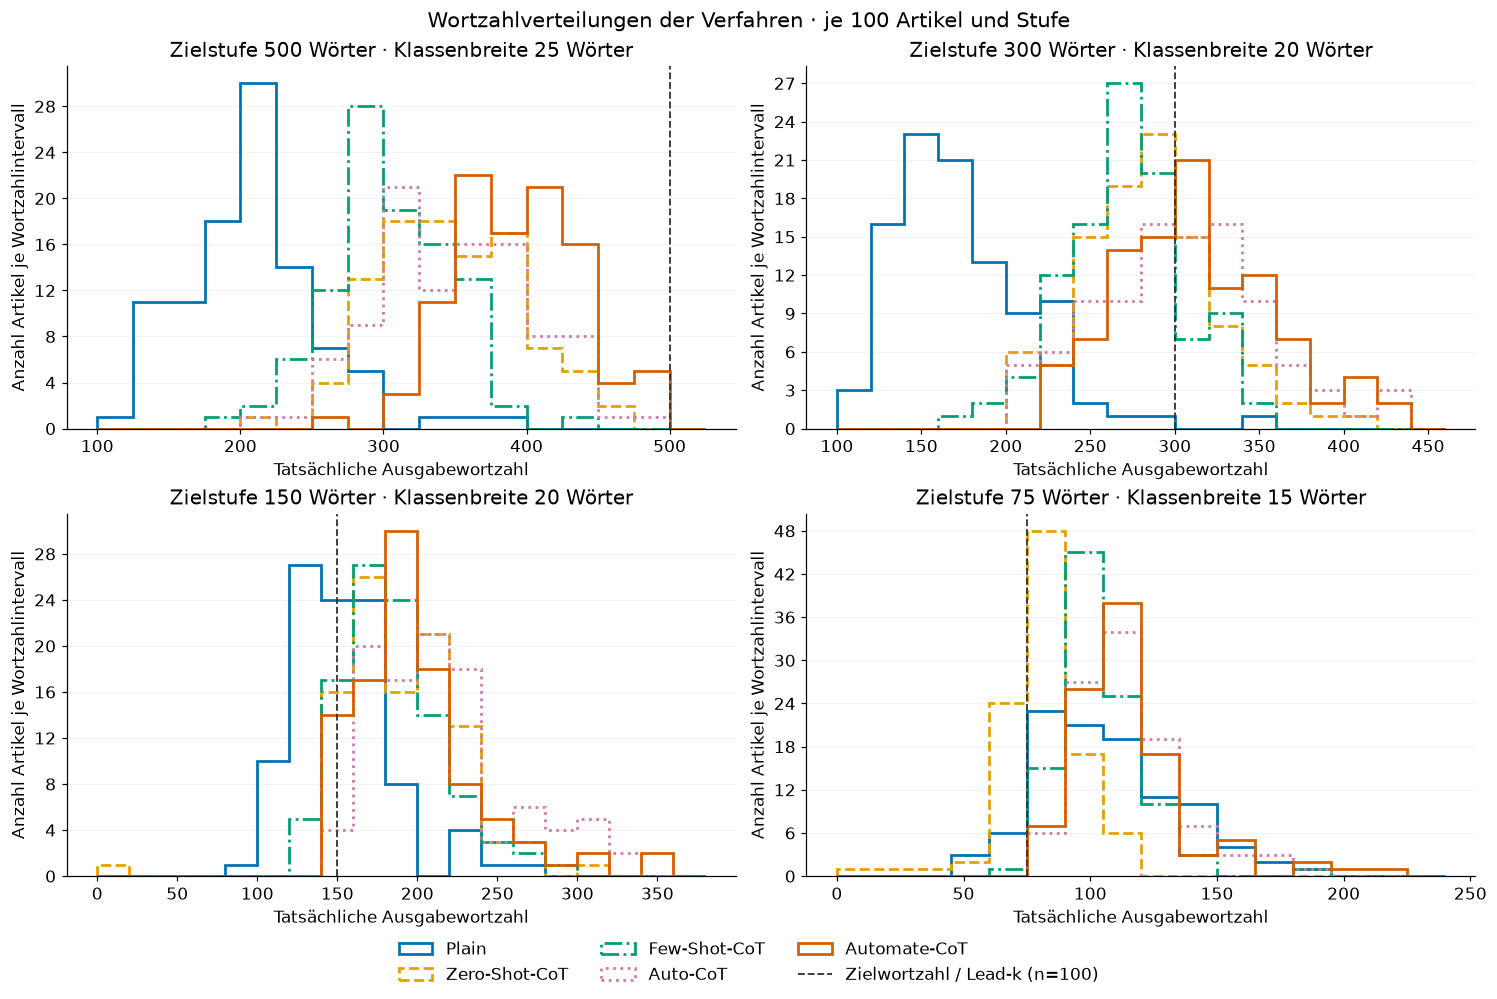

**Lesart:** Überlappende Histogramme zeigen, wo Vergleiche bei ähnlicher Länge möglich sein könnten. Die anschließende Supportprüfung verlangt zusätzlich ausreichend gepaarte Artikel und lokale Beobachtungen; die bloße Überlappung einzelner Balken genügt dafür nicht.

In [8]:
histogram_rows=[]
fig,axes=plt.subplots(2,2,figsize=(13.5,9),layout='constrained')
for ax,stage in zip(axes.flat,STAGES):
    stage_data=article[article.stage_target_words.eq(stage)]
    assert stage_data.loc[stage_data.method.eq('lead_k'),'W'].eq(stage).all()
    bin_width=max(5,int(np.ceil((stage_data.W.max()-stage_data.W.min())/18/5))*5)
    edges=np.arange(np.floor(stage_data.W.min()/bin_width)*bin_width,
                    np.ceil(stage_data.W.max()/bin_width)*bin_width+bin_width*1.01,bin_width)
    for mi,method in enumerate(GENERATIVE):
        values=stage_data.loc[stage_data.method.eq(method),'W'].to_numpy()
        counts,_=np.histogram(values,bins=edges)
        assert counts.sum()==100
        ax.hist(values,bins=edges,histtype='step',lw=1.8,color=METHOD_COLORS[method],
                linestyle=['-','--','-.',':','-'][mi],label=NAMES[method])
        histogram_rows.extend(dict(method=method,stage_target_words=stage,lower=edges[i],upper=edges[i+1],
            n=int(n),right_edge_inclusive=i==len(counts)-1) for i,n in enumerate(counts))
    ax.axvline(stage,color='#333333',ls='--',lw=1.2,label='Zielwortzahl / Lead-k (n=100)')
    ax.set(xlabel='Tatsächliche Ausgabewortzahl',ylabel='Anzahl Artikel je Wortzahlintervall',
           title=f'Zielstufe {stage} Wörter · Klassenbreite {bin_width} Wörter')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True));ax.grid(axis='y',alpha=.15)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=3,frameon=False)
fig.suptitle('Wortzahlverteilungen der Verfahren · je 100 Artikel und Stufe',fontsize=14)
export(pd.DataFrame(histogram_rows),'grafik_histogramme_wortzahlen')
savefig(fig,'03_histogramme_tatsaechlicher_wortzahlen')
display(Markdown('**Lesart:** Überlappende Histogramme zeigen, wo Vergleiche bei ähnlicher Länge möglich '
    'sein könnten. Die anschließende Supportprüfung verlangt zusätzlich ausreichend gepaarte Artikel '
    'und lokale Beobachtungen; die bloße Überlappung einzelner Balken genügt dafür nicht.'))


## 4. Analyse B: Überlappung tatsächlicher Wortlängen

Für alle 15 Methodenpaare und vier Stufen werden Minima, Maxima und Perzentile
berichtet. Ein Min–Max-Schnitt allein reicht nicht als Vergleichsgrundlage.

**Primärer gestützter Bereich:** Schnitt der 5.–95.-Perzentilbereiche. Beide Methoden
müssen dort mindestens 20 Ausgaben haben; mindestens 20 derselben Artikel müssen
mit beiden Ausgaben im Bereich liegen. Zusätzlich müssen an **beiden Wortzahlen
jedes Standardisierungsartikels** bei beiden Methoden jeweils mindestens fünf
Ausgaben im Umfeld ±max(5 Wörter, 10 % der Wortzahl) vorliegen. Diese lokale Prüfung
vermeidet Vergleiche über größere empirische Lücken. Es erfolgt keine Auswahl nach
Retention oder Höhe eines Methodenvorteils. Weniger als 30 unterstützende Artikel
werden als kleine Gruppe markiert, unter 20 wird kein belastbarer Modellvergleich publiziert.

Sensitivitäten: derselbe lokale Filter und dieselbe Mindestgröße, aber einmal der
breitere Min–Max-Schnitt und einmal der engere 10.–90.-Perzentilschnitt.
Die Kriterien sind transparente operative Grenzen, keine formalen Identifikationsbeweise.

In [9]:
quantiles=article.groupby(['method','stage_target_words']).W.quantile([0,.05,.10,.25,.50,.75,.90,.95,1]).unstack()
quantiles.columns=['min','p05','p10','p25','p50','p75','p90','p95','max']
quantiles=quantiles.reset_index()
export(quantiles,'B_wortzahlverteilungen_24_gruppen')
display(quantiles.round(2))
SUPPORT_DEFS={'central95':(.05,.95),'broad':(0.,1.),'central80':(.10,.90)}

def support_for(methods,stage,definition):
    sub=article[article.stage_target_words.eq(stage)&article.method.isin(methods)]
    wide=sub.pivot(index='article_id',columns='method',values='W').reindex(index=IDS,columns=methods)
    loq,hiq=SUPPORT_DEFS[definition]
    lower=float(max(wide[m].quantile(loq) for m in methods))
    upper=float(min(wide[m].quantile(hiq) for m in methods))
    in_range=wide.ge(lower)&wide.le(upper)&wide.gt(0)
    n_by_method={m:int(in_range[m].sum()) for m in methods}
    paired=in_range.all(axis=1)
    local=paired.copy()
    for a in wide.index[paired]:
        for w in wide.loc[a].to_numpy():
            bandwidth=max(5,.1*w)
            if any(int((wide[m]-w).abs().le(bandwidth).sum())<5 for m in methods):
                local.loc[a]=False
                break
    reasons=[]
    if lower>=upper:reasons.append('kein gemeinsamer Bereich mit positiver Breite')
    if min(n_by_method.values())<MIN_SUPPORT:reasons.append('weniger als 20 Beobachtungen je Verfahren im Bereich')
    if int(local.sum())<MIN_SUPPORT:reasons.append('weniger als 20 lokal gestützte gepaarte Artikel')
    if any(m=='lead_k' for m in methods):reasons.append('Lead-k bleibt außerhalb der generativen Regression')
    return dict(lower=lower,upper=upper,n_by_method=n_by_method,
        n_paired_range=int(paired.sum()),n_supported=int(local.sum()),ids=wide.index[local].tolist(),
        estimable=not reasons,reason='; '.join(reasons) if reasons else 'gestützter explorativer Vergleich',
        small_group=0<int(local.sum())<30)

support_rows=[];supports={}
for first,second in combinations(METHODS,2):
    for stage in STAGES:
        left=article[(article.method==first)&article.stage_target_words.eq(stage)].set_index('article_id')
        right=article[(article.method==second)&article.stage_target_words.eq(stage)].set_index('article_id')
        direct=(left.W+right.W).gt(0)&(40*(left.W-right.W).abs()).le(left.W+right.W)
        for definition in SUPPORT_DEFS:
            support=support_for([first,second],stage,definition)
            supports[(first,second,stage,definition)]=support
            support_rows.append(dict(first=first,second=second,stage_target_words=stage,definition=definition,
                common_lower=support['lower'],common_upper=support['upper'],
                n_first_in_range=support['n_by_method'][first],n_second_in_range=support['n_by_method'][second],
                n_paired_range=support['n_paired_range'],n_supported_articles=support['n_supported'],
                n_direct_5pct_pairs=int(direct.sum()),estimable=support['estimable'],
                small_group=support['small_group'],status=support['reason']))
overlap=pd.DataFrame(support_rows)
export(overlap,'B_ueberlappung_60_paare_drei_definitionen')

def get_support(first,second,stage,definition='central95'):
    key=(first,second,stage,definition)
    if key not in supports:key=(second,first,stage,definition)
    return supports[key]

core_support=pd.DataFrame([dict(first=f,second=s,stage_target_words=t,
    lower=get_support(f,s,t)['lower'],upper=get_support(f,s,t)['upper'],
    n=get_support(f,s,t)['n_supported'],estimable=get_support(f,s,t)['estimable'],
    status=get_support(f,s,t)['reason']) for f,s in CONTRASTS for t in STAGES])
display(core_support.round(2))
export(core_support,'B_ueberlappung_16_hauptkontraste')
global_support={t:support_for(GENERATIVE,t,'central95') for t in STAGES}
display(pd.DataFrame([dict(stage=t,lower=s['lower'],upper=s['upper'],n=s['n_supported'],
    estimable=s['estimable'],status=s['reason']) for t,s in global_support.items()]))


,method,stage_target_words,min,p05,p10,p25,p50,p75,p90,p95,max
0,auto_cot,75,81.0,88.95,95.0,102.75,111.5,123.25,138.5,158.30,185.0
1,auto_cot,150,140.0,160.00,166.0,181.75,209.0,235.50,280.5,304.05,332.0
2,auto_cot,300,206.0,227.55,239.0,272.00,302.5,332.50,360.5,383.00,433.0
3,auto_cot,500,214.0,264.90,282.9,310.75,348.5,383.25,421.6,441.10,491.0
4,automate_cot,75,76.0,87.00,93.9,102.00,110.0,121.50,139.5,162.10,216.0
5,automate_cot,150,140.0,149.95,158.0,174.00,192.5,216.00,243.3,275.30,354.0
6,automate_cot,300,222.0,243.70,258.9,278.00,310.0,346.25,367.9,400.30,435.0
7,automate_cot,500,261.0,327.85,339.7,359.00,390.5,423.75,446.3,464.90,496.0
8,few_shot_cot,75,67.0,78.00,84.7,94.75,102.0,113.25,125.4,131.10,189.0
9,few_shot_cot,150,129.0,140.90,149.0,163.50,180.0,200.00,227.1,246.05,285.0


,first,second,stage_target_words,lower,upper,n,estimable,status
0,zero_shot_cot,plain,500,274.80,279.75,0,False,weniger als 20 Beobachtungen je Verfahren im B...
1,zero_shot_cot,plain,300,218.90,239.85,0,False,weniger als 20 Beobachtungen je Verfahren im B...
2,zero_shot_cot,plain,150,148.85,222.30,33,True,gestützter explorativer Vergleich
3,zero_shot_cot,plain,75,63.00,105.00,38,True,gestützter explorativer Vergleich
4,few_shot_cot,plain,500,236.65,279.75,2,False,weniger als 20 Beobachtungen je Verfahren im B...
5,few_shot_cot,plain,300,217.65,239.85,1,False,weniger als 20 Beobachtungen je Verfahren im B...
6,few_shot_cot,plain,150,140.90,222.30,47,True,gestützter explorativer Vergleich
7,few_shot_cot,plain,75,78.00,131.10,63,True,gestützter explorativer Vergleich
8,auto_cot,few_shot_cot,500,264.90,370.05,48,True,gestützter explorativer Vergleich
9,auto_cot,few_shot_cot,300,227.55,330.10,58,True,gestützter explorativer Vergleich


,stage,lower,upper,n,estimable,status
0,500,327.85,279.75,0,False,kein gemeinsamer Bereich mit positiver Breite;...
1,300,243.70,239.85,0,False,kein gemeinsamer Bereich mit positiver Breite;...
2,150,160.00,222.30,6,False,weniger als 20 lokal gestützte gepaarte Artikel
3,75,88.95,105.00,0,False,weniger als 20 lokal gestützte gepaarte Artikel


## 5. Analyse C: längenkontrollierte Regression

### Modellklasse und begründete Alternative zum GLMM

Die verfügbare `BinomialBayesMixedGLM`-Implementierung verlangt eine binäre 0/1-Antwort
und nimmt die geforderten gruppierten binomialen Zählwerte nicht direkt an. R und
eine entsprechende GLMM-Laufzeit sind hier nicht verfügbar. Eine Expansion in
scheinbar unabhängige Einzelurteile wird vermieden. Stattdessen wird die im Auftrag
zugelassene Alternative verwendet: **binomiales GLM auf [retained, gültig−retained]
mit festen Artikeleffekten und artikelweise clusterrobusten Unsicherheiten**.
Das ist kein zufälliges Interzeptmodell und wird nicht als gleichwertige GLMM-Schätzung ausgegeben.

Primärmodell:
\[
K_{imt}\mid V_{imt}\sim Binomial(V_{imt},p_{imt}),\qquad
\operatorname{logit}(p_{imt})=\alpha_i+\gamma_{mt}
+\beta_t(W_{imt}-t)/100.
\]

100 Artikeleffekte (Referenzkodierung), 20 Methode-Stufen-Zellen und vier Längeneffekte
ergeben 123 Parameter. Das flexible Vergleichsmodell ersetzt die vier linearen Effekte
durch je drei zentrierte natürliche kubische Spline-Basisfunktionen (131 Parameter).
Die Basis wird je Stufe geschätzt, nicht über alle Stufen gepoolt. Das lineare Modell
bleibt wegen seiner Transparenz die vorab gewählte Hauptdarstellung; die flexible
Variante zeigt mögliche Formabhängigkeit. Es gibt keine Auswahl nach günstigen Kontrastvorzeichen.

Abhängigkeiten aller Fakten, Methoden und Stufen innerhalb desselben Artikels werden
bei Kovarianz und Resampling auf Artikelebene zusammengehalten. Die binomiale Varianz
ist eine Arbeitsannahme; robuste Kovarianzen und Cluster-Bootstrap korrigieren keine
falsch spezifizierte mittlere Antwortfunktion. Feste Artikeleffekte konditionieren auf
die vorliegenden Artikel und erlauben keine automatische Übertragung auf neue Artikel.

Technische Quellen: [Statsmodels GLM](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.html),
[Mixed-GLM-Implementierung](https://www.statsmodels.org/stable/_modules/statsmodels/genmod/bayes_mixed_glm.html),
[Artikel-Cluster-Kovarianz](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_cluster.html),
[natürliche Splines in Patsy](https://patsy.readthedocs.io/en/latest/spline-regression.html).

In [10]:
model_data=article[article.method.isin(GENERATIVE)].sort_values(CELL).reset_index(drop=True).copy()
assert len(model_data)==2000
MODEL_CELLS=[(m,t) for m in GENERATIVE for t in STAGES]
cell_map={key:i for i,key in enumerate(MODEL_CELLS)}
article_map={a:i for i,a in enumerate(IDS)}
N_ART=len(IDS)
ART_INDEX=model_data.article_id.map(article_map).to_numpy()
Y=np.column_stack([model_data.n_retained,model_data.n_valid-model_data.n_retained]).astype(float)
SPLINE_INFO={}
for stage in STAGES:
    w=model_data.loc[model_data.stage_target_words.eq(stage),'W'].to_numpy()/100
    spline=patsy.dmatrix("cr(w, df=3, constraints='center') - 1",{'w':w},return_type='dataframe')
    SPLINE_INFO[stage]=spline.design_info

def design(frame,kind):
    n=len(frame)
    base=np.zeros((n,20+99),dtype=float)
    cell_idx=np.array([cell_map[(m,int(t))] for m,t in zip(frame.method,frame.stage_target_words)])
    ai=frame.article_id.map(article_map).to_numpy()
    assert np.isfinite(ai).all()
    ai=ai.astype(int)
    base[np.arange(n),cell_idx]=1
    has_dummy=ai>0
    base[np.flatnonzero(has_dummy),20+ai[has_dummy]-1]=1
    length_columns=[]
    for stage in STAGES:
        selected=frame.stage_target_words.eq(stage).to_numpy()
        if kind=='linear':
            block=np.zeros((n,1));block[selected,0]=(frame.loc[selected,'W'].to_numpy()-stage)/100
        else:
            block=np.zeros((n,3))
            if selected.any():
                block[selected]=np.asarray(patsy.build_design_matrices([SPLINE_INFO[stage]],
                    {'w':frame.loc[selected,'W'].to_numpy()/100})[0])
        length_columns.append(block)
    return np.column_stack([base]+length_columns)

models={};diagnostic_rows=[];coefficient_rows=[]
for kind in ['linear','spline']:
    X=design(model_data,kind)
    names=[f'{m}:{t}' for m,t in MODEL_CELLS]+[f'article_{a}' for a in IDS[1:]]
    names += [f'length_{t}'+(f'_basis{b}' if kind=='spline' else '')
              for t in STAGES for b in (range(1,4) if kind=='spline' else [1])]
    started=time.perf_counter()
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        result=sm.GLM(Y,X,family=sm.families.Binomial()).fit(maxiter=100,tol=1e-10,
            cov_type='cluster',cov_kwds={'groups':model_data.article_id.to_numpy(),'use_correction':True})
    seconds=time.perf_counter()-started
    cov=np.asarray(result.cov_params())
    eig=la.eigvalsh((cov+cov.T)/2)
    stable=bool(result.converged and np.isfinite(result.params).all() and
        np.linalg.matrix_rank(X)==X.shape[1] and np.isfinite(cov).all() and eig.min()>-1e-8)
    models[kind]=dict(X=X,result=result,beta=np.asarray(result.params),cov=cov,stable=stable,names=names)
    diagnostic_rows.append(dict(model=kind,n_rows=len(X),n_parameters=X.shape[1],design_rank=np.linalg.matrix_rank(X),
        n_article_clusters=N_ART,converged=result.converged,iterations=result.fit_history.get('iteration'),
        max_abs_coefficient=float(abs(result.params).max()),design_condition=float(np.linalg.cond(X)),
        covariance_rank=np.linalg.matrix_rank(cov),min_covariance_eigenvalue=float(eig.min()),
        max_abs_score=float(abs(result.model.score(result.params)).max()),
        pearson_ratio=float(result.pearson_chi2/result.df_resid),deviance=float(result.deviance),
        fit_seconds=seconds,warning_text=' | '.join(str(w.message) for w in captured),stable=stable))
    for i,name in enumerate(names):
        coefficient_rows.append(dict(model=kind,term=name,estimate=result.params[i],
            cluster_robust_se=float(np.sqrt(max(cov[i,i],0)))))
    influence=result.get_influence(observed=False)
    diagnostics=model_data[CELL+['W','n_retained','n_valid','retention_observed']].copy()
    diagnostics['predicted']=result.predict()
    diagnostics['pearson_residual']=result.resid_pearson
    diagnostics['leverage']=influence.hat_matrix_diag
    export(diagnostics,f'C_residuen_und_hebelwerte_{kind}')
diagnostics_table=pd.DataFrame(diagnostic_rows)
export(diagnostics_table,'C_modelldiagnostik')
export(pd.DataFrame(coefficient_rows),'C_regressionskoeffizienten_clusterrobuste_se')
display(diagnostics_table)
assert diagnostics_table.stable.all(), 'Modellinstabilität: keine verlässlichen Standardisierungen ausgeben.'
display(Markdown('Die robuste Kovarianz ist erwartungsgemäß rangreduziert: Scorebeiträge der '
    'artikelweisen Interzepte summieren sich innerhalb ihrer Cluster nahezu zu null. '
    'Es wird kein gemeinsamer Wald-Test aller Koeffizienten daraus abgeleitet. '
    'Die Kontrastintervalle beruhen zusätzlich auf vollständigen Artikelbootstrap-Anpassungen.'))


,model,n_rows,n_parameters,design_rank,n_article_clusters,converged,iterations,max_abs_coefficient,...,covariance_rank,min_covariance_eigenvalue,max_abs_score,pearson_ratio,deviance,fit_seconds,warning_text,stable
0,linear,2000,123,123,100,True,5,1.997302,...,23,-1.119117e-15,1.631556e-11,0.651070,1270.384288,0.046486,,True
1,spline,2000,131,131,100,True,5,2.618791,...,31,-6.182403e-16,4.328664e-12,0.635439,1225.808864,0.045314,,True


Die robuste Kovarianz ist erwartungsgemäß rangreduziert: Scorebeiträge der artikelweisen Interzepte summieren sich innerhalb ihrer Cluster nahezu zu null. Es wird kein gemeinsamer Wald-Test aller Koeffizienten daraus abgeleitet. Die Kontrastintervalle beruhen zusätzlich auf vollständigen Artikelbootstrap-Anpassungen.

### Ergänzende Grafik: Beobachtete Retention in Wortzahlbereichen

Die Zellen zeigen den **ungewichteten Mittelwert der Artikelretention** in gemeinsamen Wortzahlklassen sowie die Zahl der Artikel. Bei weniger als fünf Artikeln wird kein Mittelwert angezeigt. Graue Zellen sind dünn oder gar nicht besetzt und bedeuten nicht 0 % Retention. Die Breite richtet sich nach der Zielstufe. Diese deskriptive Ansicht vergleicht unterschiedliche Artikelgruppen; sie ist keine längenkontrollierte Schätzung und zeigt keine Unsicherheitsintervalle.

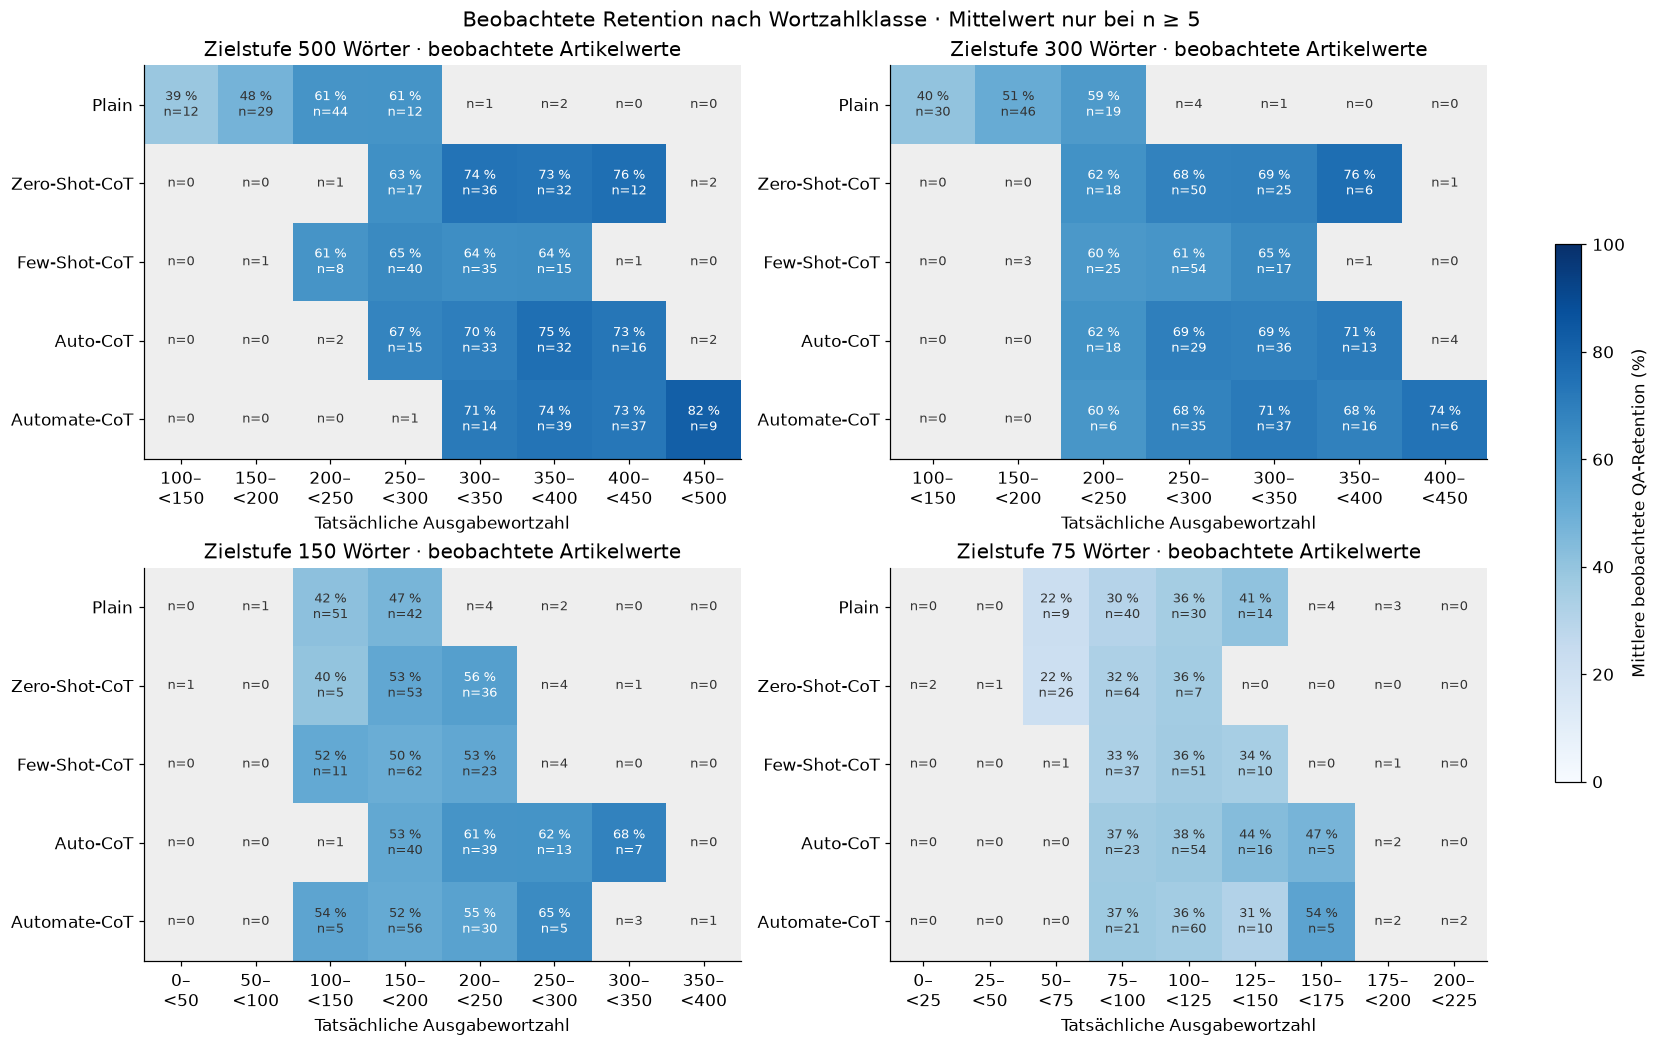

**Beobachtung:** 73 von 160 Verfahren-Wortzahl-Zellen enthalten mindestens fünf Artikel. Die übrigen Zellen bleiben ohne Mittelwert; die Artikelzusammensetzung kann sich zwischen Verfahren und Wortzahlklassen unterscheiden.

In [11]:
binned_rows=[]
fig,axes=plt.subplots(2,2,figsize=(15,9.4),layout='constrained')
cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#EEEEEE')
for ax,stage in zip(axes.flat,STAGES):
    sub=article[article.stage_target_words.eq(stage) & article.method.isin(GENERATIVE)].copy()
    width={500:50,300:50,150:50,75:25}[stage]
    edges=np.arange(np.floor(sub.W.min()/width)*width,(np.floor(sub.W.max()/width)+1)*width+width*.5,width)
    sub['word_bin']=pd.cut(sub.W,edges,right=False,include_lowest=True)
    grouped=sub.groupby(['method','word_bin'],observed=False).agg(n=('article_id','size'),retention=('retention_observed','mean'))
    bins=sub.word_bin.cat.categories
    means=grouped.retention.unstack().reindex(index=GENERATIVE,columns=bins)*100
    counts=grouped.n.unstack().reindex(index=GENERATIVE,columns=bins,fill_value=0)
    plotted=means.where(counts.ge(5))
    im=ax.imshow(np.ma.masked_invalid(plotted.to_numpy()),cmap=cmap,vmin=0,vmax=100,aspect='auto')
    for i,method in enumerate(GENERATIVE):
        for j,interval in enumerate(bins):
            n=int(counts.iloc[i,j]);mean=means.iloc[i,j]
            text=f'{mean:.0f} %\nn={n}' if n>=5 else f'n={n}'
            ax.text(j,i,text,ha='center',va='center',fontsize=8.5,color='white' if n>=5 and mean>55 else '#333333')
            binned_rows.append(dict(method=method,stage_target_words=stage,lower=interval.left,upper=interval.right,
                n=n,mean_retention_percent=mean,displayed=n>=5))
    assert int(counts.to_numpy().sum())==500
    ax.set(xticks=range(len(bins)),xticklabels=[f'{int(b.left)}–\n<{int(b.right)}' for b in bins],
           yticks=range(5),yticklabels=[NAMES[m] for m in GENERATIVE],xlabel='Tatsächliche Ausgabewortzahl',
           title=f'Zielstufe {stage} Wörter · beobachtete Artikelwerte')
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.6,label='Mittlere beobachtete QA-Retention (%)')
fig.suptitle('Beobachtete Retention nach Wortzahlklasse · Mittelwert nur bei n ≥ 5',fontsize=14)
export(pd.DataFrame(binned_rows),'grafik_retention_nach_wortzahlklassen')
savefig(fig,'04_beobachtete_retention_nach_wortzahlklasse')
shown_bins=pd.DataFrame(binned_rows)
display(Markdown(f'**Beobachtung:** {int(shown_bins.displayed.sum())} von {len(shown_bins)} '
    'Verfahren-Wortzahl-Zellen enthalten mindestens fünf Artikel. Die übrigen Zellen bleiben ohne Mittelwert; '
    'die Artikelzusammensetzung kann sich zwischen Verfahren und Wortzahlklassen unterscheiden.'))


## 6. Analyse D: standardisierte Methodenvergleiche

Jeder gestützte Paarvergleich hat seine eigene Artikelpopulation. Für jeden dort
verbleibenden Artikel werden seine **beiden beobachteten Wortzahlen** gleich gewichtet.
Bei jeder dieser Wortzahlen werden für beide Methoden Vorhersagen unter demselben
Artikeleffekt und derselben Stufe gebildet; anschließend wird über Wortzahlen und
Artikel gemittelt. Die Differenz ist auf der ursprünglichen Prozentpunktskala.

Die Rohdifferenz auf denselben ausgewählten Artikeln wird separat mitgeführt.
Damit lässt sich eine durch die Überlappungsauswahl veränderte Artikelpopulation von
der anschließenden Modellstandardisierung unterscheiden. Eine Differenz zwischen
Gesamtrohwert und standardisiertem Wert ist kein kausal erklärter Wortlängenanteil.

Nicht hinreichend gestützte Vergleiche bekommen **keinen** veröffentlichten Modellwert.
Alle fünf generativen Verfahren werden paarweise geprüft, damit insbesondere die
75-Wörter-Frage zu Auto-CoT gegenüber sämtlichen anderen generativen Methoden sichtbar bleibt.

In [12]:
comparison_specs=[]
for first,second in combinations(GENERATIVE,2):
    for stage in STAGES:
        for definition in SUPPORT_DEFS:
            support=get_support(first,second,stage,definition)
            if not support['estimable']:continue
            ids=support['ids']
            left=article[(article.method==first)&article.stage_target_words.eq(stage)].set_index('article_id').loc[ids]
            right=article[(article.method==second)&article.stage_target_words.eq(stage)].set_index('article_id').loc[ids]
            reference=pd.DataFrame({'article_id':np.repeat(ids,2),'W':np.column_stack([left.W,right.W]).ravel(),
                                    'stage_target_words':stage})
            comparison_specs.append(dict(first=first,second=second,stage=stage,definition=definition,
                support=support,reference=reference,
                reference_article_indices=reference.article_id.map(article_map).to_numpy(),
                raw_same_articles_pp=float(100*(left.retention_observed-right.retention_observed).mean())))

def standardized_point(spec,kind):
    ref=spec['reference']
    xa=design(ref.assign(method=spec['first']),kind)
    xb=design(ref.assign(method=spec['second']),kind)
    beta=models[kind]['beta']
    return float(100*np.mean(expit(xa@beta)-expit(xb@beta))),xa,xb

point_rows=[]
for spec in comparison_specs:
    for kind in models:
        point,xa,xb=standardized_point(spec,kind)
        point_rows.append(dict(first=spec['first'],second=spec['second'],stage_target_words=spec['stage'],
            definition=spec['definition'],model=kind,adjusted_difference_pp=point,
            raw_same_articles_pp=spec['raw_same_articles_pp'],n_articles=spec['support']['n_supported'],
            common_lower=spec['support']['lower'],common_upper=spec['support']['upper']))
points=pd.DataFrame(point_rows)
export(points,'D_gestuetzte_standardisierte_punktschaetzer')
display(points[(points.definition=='central95')&(points.model=='linear')].round(3))


,first,second,stage_target_words,definition,model,adjusted_difference_pp,raw_same_articles_pp,n_articles,common_lower,common_upper
0,plain,zero_shot_cot,150,central95,linear,-2.799,-5.262,33,148.85,222.30
4,plain,zero_shot_cot,75,central95,linear,-0.779,1.171,38,63.00,105.00
10,plain,few_shot_cot,150,central95,linear,-0.849,-4.269,47,140.90,222.30
16,plain,few_shot_cot,75,central95,linear,-1.255,-1.416,63,78.00,131.10
24,plain,auto_cot,75,central95,linear,-3.187,-3.256,59,88.95,156.10
30,plain,automate_cot,150,central95,linear,-1.458,-1.369,29,149.95,222.30
34,plain,automate_cot,75,central95,linear,-1.027,-1.903,65,87.00,156.10
40,zero_shot_cot,few_shot_cot,500,central95,linear,3.855,6.019,45,274.80,370.05
46,zero_shot_cot,few_shot_cot,300,central95,linear,4.996,6.881,75,218.90,330.10
52,zero_shot_cot,few_shot_cot,150,central95,linear,1.927,3.593,77,148.85,246.05


## 7. Bootstrap und Unsicherheit

Es werden **10.000 vollständige Modellanpassungen je Modell** ausgeführt. Jede Ziehung
resampelt die 100 Artikel mit Zurücklegen und nimmt alle 20 generativen
Methoden-Stufen-Ausgaben des gezogenen Artikels gemeinsam mit. Die gleichen
Ziehungsgewichte gelten für beide Modelle und alle Vergleiche. Wiederholte Kopien
identischer Artikel werden äquivalent über ganzzahlige Häufigkeitsgewichte in der
binomialen Likelihood abgebildet; die festen Artikeleffekte werden für die vorhandenen
Artikel neu geschätzt und auf einen in der Ziehung vorhandenen Referenzartikel umkodiert.

Auch die gemeinsame empirische Standardisierungsverteilung wird mit denselben
Artikelhäufigkeiten neu gewichtet. Das erfasst sowohl Schätzvariation des Modells
als auch Variation der ausgewählten Artikel und ihrer Referenzwortzahlen. Die
ursprünglich definierten Perzentilgrenzen, lokalen Supportregeln und Spline-Knoten
bleiben fixiert; Unsicherheit einer erneuten Auswahl dieser Grenzen ist nicht enthalten.

Die 2,5-%-/97,5-%-Quantile ergeben punktweise 95-%-Perzentilintervalle ohne Korrektur
für Mehrfachvergleiche. Modellanpassungsfehler und Ziehungen ohne Referenzartikel
werden gezählt. Unter 99 % gültigen Ziehungen wird ein Vergleich nicht als zuverlässig
ausgegeben. Kein stillschweigender Ersatz fehlgeschlagener Anpassungen.

Ein kleiner lokal erzeugter Worker enthält ausschließlich diese binomialen
Anpassungen. Ein Cache im **neuen** Ergebnisordner wird nur wiederverwendet, wenn
Designmatrix, Zählwerte, ursprüngliche Parameterschätzung, alle 10.000 Ziehungen,
Worker-Code und Softwareversionen im Fingerabdruck übereinstimmen. Es werden keine
Ergebnisse aus einem anderen Datenstand rekonstruiert oder ungeprüft geladen.

In [13]:
from faktenretention import analysis_bootstrap_worker as worker
worker_source=Path(worker.__file__).read_text()
from faktenretention import analysis_bootstrap_worker as worker
draws=np.random.default_rng(SEED).integers(0,N_ART,size=(B,N_ART))
bootstrap_counts=np.zeros((B,N_ART),dtype=np.int16)
np.add.at(bootstrap_counts,(np.repeat(np.arange(B),N_ART),draws.ravel()),1)
assert bootstrap_counts.sum(axis=1).tolist()==[N_ART]*B
boot_coefficients={};bootstrap_fit_rows=[]
weight_validation=[]
for kind,state in models.items():
    worker.initialize(state['X'],Y,ART_INDEX,state['beta'])
    # Häufigkeitsgewichte unabhängig gegen physisch wiederholte Artikelzeilen prüfen,
    # insbesondere die neue Referenzkodierung, wenn Originalartikel 1 nicht gezogen wurde.
    test_indices=[int(np.flatnonzero(bootstrap_counts[:,0]>0)[0]),
                  int(np.flatnonzero(bootstrap_counts[:,0]==0)[0])]
    for draw in test_indices:
        counts=bootstrap_counts[draw]
        reference=int(np.flatnonzero(counts>0)[0])
        columns=np.ones(state['X'].shape[1],dtype=bool)
        for ai in range(1,N_ART):
            if counts[ai]==0 or ai==reference:columns[20+ai-1]=False
        expanded=np.repeat(np.arange(len(model_data)),counts[ART_INDEX])
        direct_fit=sm.GLM(Y[expanded],state['X'][expanded][:,columns],family=sm.families.Binomial()).fit(
            maxiter=100,tol=1e-10)
        weighted,records_check=worker.fit_batch(counts[None,:])
        included=counts[ART_INDEX]>0
        direct_predictions=direct_fit.predict(state['X'][included][:,columns])
        weighted_predictions=expit(state['X'][included]@weighted[0])
        max_error=float(abs(direct_predictions-weighted_predictions).max())
        assert records_check[0][0] and direct_fit.converged and max_error<1e-7
        weight_validation.append(dict(model=kind,draw=draw,original_reference_absent=bool(counts[0]==0),
            n_expanded_rows=len(expanded),max_prediction_difference=max_error,passed=True))
export(pd.DataFrame(weight_validation),'bootstrap_haufigkeitsgewichte_unabhaengig_validiert')
for kind,state in models.items():
    fingerprint=hashlib.sha256(state['X'].tobytes()+Y.tobytes()+state['beta'].tobytes()+
        bootstrap_counts.tobytes()+worker_source.encode()+json.dumps(software,sort_keys=True).encode()).hexdigest()
    cache=DATA_DIR / f'caches/11_statistische_laengenkontrolle/bootstrap_10000_{kind}.npz'
    cached=False
    if cache.is_file():
        with np.load(cache,allow_pickle=False) as archive:
            if str(archive['fingerprint'])==fingerprint:
                coefficients=archive['coefficients'].copy()
                records=json.loads(str(archive['records']))
                cached=True
    started=time.perf_counter()
    if not cached:
        raise RuntimeError("Bootstrap-Cache fehlt oder passt nicht. python 05_analyze.py --prepare "
                           "ausführen und die dokumentierte Analyseumgebung verwenden; keine Neuberechnung.")

    assert coefficients.shape==(B,state['X'].shape[1]) and len(records)==B
    success=np.array([bool(r[0]) for r in records])
    assert np.isfinite(coefficients[success]).all()
    boot_coefficients[kind]=coefficients
    bootstrap_fit_rows.append(dict(model=kind,n_requested=B,n_success=int(success.sum()),
        n_failed=int((~success).sum()),n_warning_fits=sum(bool(r[2]) for r in records),
        max_iterations=max(r[1] for r in records),seconds_this_run=time.perf_counter()-started,
        cache_used=cached,fingerprint=fingerprint))
    failures=pd.DataFrame([dict(draw=i,converged=r[0],iterations=r[1],message=r[2])
                           for i,r in enumerate(records) if not r[0] or r[2]],
                          columns=['draw','converged','iterations','message'])
    export(failures,f'bootstrap_numerische_hinweise_{kind}')
bootstrap_fits=pd.DataFrame(bootstrap_fit_rows)
export(bootstrap_fits,'bootstrap_anpassungsdiagnostik')
display(bootstrap_fits.drop(columns='fingerprint'))


,model,n_requested,n_success,n_failed,n_warning_fits,max_iterations,seconds_this_run,cache_used
0,linear,10000,10000,0,0,4,0.001327,True
1,spline,10000,10000,0,0,5,0.001558,True


In [14]:
bootstrap_comparisons=[]
for spec in comparison_specs:
    for kind in models:
        point,xa,xb=standardized_point(spec,kind)
        reference_ai=spec['reference_article_indices']
        distributions=np.full(B,np.nan)
        for start in range(0,B,200):
            end=min(start+200,B)
            coefficients=boot_coefficients[kind][start:end]
            weights=bootstrap_counts[start:end,reference_ai]
            denominator=weights.sum(axis=1)
            probabilities_a=expit(coefficients@xa.T)
            probabilities_b=expit(coefficients@xb.T)
            numerator=((probabilities_a-probabilities_b)*weights).sum(axis=1)
            distributions[start:end]=np.divide(100*numerator,denominator,
                out=np.full(end-start,np.nan),where=denominator>0)
        finite=np.isfinite(distributions)
        reliable=int(finite.sum())>=int(.99*B)
        low,high=np.nanquantile(distributions,[.025,.975]) if reliable else [np.nan,np.nan]
        bootstrap_comparisons.append(dict(first=spec['first'],second=spec['second'],stage_target_words=spec['stage'],
            definition=spec['definition'],model=kind,adjusted_difference_pp=point if reliable else np.nan,
            ci_low_pp=low,ci_high_pp=high,n_bootstrap_valid=int(finite.sum()),n_bootstrap_missing=int((~finite).sum()),
            reliable=reliable,n_articles=spec['support']['n_supported'],n_reference_points=len(spec['reference']),
            common_lower=spec['support']['lower'],common_upper=spec['support']['upper'],
            raw_same_articles_pp=spec['raw_same_articles_pp']))
controlled=pd.DataFrame(bootstrap_comparisons)
export(controlled,'D_alle_gestuetzten_kontraste_95ci')

def oriented_result(first,second,stage,definition='central95',kind='linear'):
    rows=controlled[(controlled['first']==first)&(controlled.second==second)&
        controlled.stage_target_words.eq(stage)&controlled.definition.eq(definition)&controlled.model.eq(kind)]
    if len(rows):return rows.iloc[0].copy()
    rows=controlled[(controlled['first']==second)&(controlled.second==first)&
        controlled.stage_target_words.eq(stage)&controlled.definition.eq(definition)&controlled.model.eq(kind)]
    if not len(rows):return None
    row=rows.iloc[0].copy()
    row['first'],row['second']=first,second
    row['adjusted_difference_pp']=-row.adjusted_difference_pp
    row['raw_same_articles_pp']=-row.raw_same_articles_pp
    row['ci_low_pp'],row['ci_high_pp']=-row.ci_high_pp,-row.ci_low_pp
    return row

core_rows=[]
for original in original_contrasts.itertuples():
    first,second,stage=original.first,original.second,original.stage_target_words
    support=get_support(first,second,stage)
    adjusted=oriented_result(first,second,stage)
    reliable=adjusted is not None and bool(adjusted.reliable)
    core_rows.append(dict(first=first,second=second,contrast=original.contrast,stage_target_words=stage,
        original_difference_pp=original.mean,original_ci_low_pp=original.ci_low,original_ci_high_pp=original.ci_high,
        controlled_difference_pp=adjusted.adjusted_difference_pp if reliable else np.nan,
        controlled_ci_low_pp=adjusted.ci_low_pp if reliable else np.nan,
        controlled_ci_high_pp=adjusted.ci_high_pp if reliable else np.nan,
        raw_same_articles_pp=adjusted.raw_same_articles_pp if reliable else np.nan,
        common_lower=support['lower'],common_upper=support['upper'],
        n_first_in_range=support['n_by_method'][first],n_second_in_range=support['n_by_method'][second],
        n_supported_articles=support['n_supported'],n_reference_points=2*support['n_supported'],
        reliable=reliable,status=('kleine Gruppe (<30 Artikel)' if support['small_group'] else 'gestützt')
            if reliable else 'nicht zuverlässig schätzbar: '+support['reason']))
core_table=pd.DataFrame(core_rows)
export(core_table,'haupttabelle_16_originale_und_laengenkontrollierte_kontraste')
display(core_table.drop(columns=['first','second']).round(3))


,contrast,stage_target_words,original_difference_pp,original_ci_low_pp,original_ci_high_pp,controlled_difference_pp,controlled_ci_low_pp,controlled_ci_high_pp,...,common_lower,common_upper,n_first_in_range,n_second_in_range,n_supported_articles,n_reference_points,reliable,status
0,Zero-Shot-CoT − Plain,500,16.997,14.294,19.768,NaN,NaN,NaN,...,274.80,279.75,4,3,0,0,False,nicht zuverlässig schätzbar: weniger als 20 Be...
1,Zero-Shot-CoT − Plain,300,17.843,15.113,20.575,NaN,NaN,NaN,...,218.90,239.85,6,11,0,0,False,nicht zuverlässig schätzbar: weniger als 20 Be...
2,Zero-Shot-CoT − Plain,150,8.523,5.587,11.325,2.799,0.106,5.513,...,148.85,222.30,77,47,33,66,True,gestützt
3,Zero-Shot-CoT − Plain,75,-4.874,-7.574,-2.247,0.779,-1.381,3.017,...,63.00,105.00,89,49,38,76,True,gestützt
4,Few-Shot-CoT − Plain,500,9.299,6.754,11.883,NaN,NaN,NaN,...,236.65,279.75,20,17,2,4,False,nicht zuverlässig schätzbar: weniger als 20 Be...
5,Few-Shot-CoT − Plain,300,11.032,8.513,13.572,NaN,NaN,NaN,...,217.65,239.85,14,11,1,2,False,nicht zuverlässig schätzbar: weniger als 20 Be...
6,Few-Shot-CoT − Plain,150,5.719,3.275,8.147,0.849,-1.411,3.134,...,140.90,222.30,82,57,47,94,True,gestützt
7,Few-Shot-CoT − Plain,75,0.750,-1.676,3.170,1.255,-0.840,3.461,...,78.00,131.10,91,69,63,126,True,gestützt
8,Auto-CoT − Few-Shot-CoT,500,7.146,4.894,9.481,2.821,0.568,5.085,...,264.90,370.05,60,83,48,96,True,gestützt
9,Auto-CoT − Few-Shot-CoT,300,7.119,4.980,9.318,3.369,1.377,5.444,...,227.55,330.10,69,84,58,116,True,gestützt


### Abbildung 1: Retention und tatsächliche Wortlänge

Punkte und die unteren Verteilungsstreifen zeigen tatsächlich beobachtete Werte.
Die Modellkurven sind für denselben Satz von 100 Artikeleffekten standardisiert und
werden nur im eigenen zentralen 5.–95.-Perzentilbereich der jeweiligen Methode mit
lokaler Unterstützung gezeichnet. **Das begründet keinen gemeinsamen Vergleichsbereich
aller Methoden.** Die paarweisen Standardisierungen verwenden jeweils ihre eigene,
strengere Überlappungsauswahl. Lead-k erscheint nur als beobachteter Referenzpunkt.

Bänder: punktweise 95-%-Intervalle der Kurven aus der artikelweise clusterrobusten
Kovarianz und t₉₉-Approximation auf der Logit-Skala der gemittelten Vorhersage.
Die Kontrastintervalle in der folgenden Abbildung stammen dagegen aus den vollständigen
10.000 Artikelbootstrap-Anpassungen. Beide enthalten keine Unsicherheit über die QA-Labelrichtigkeit.

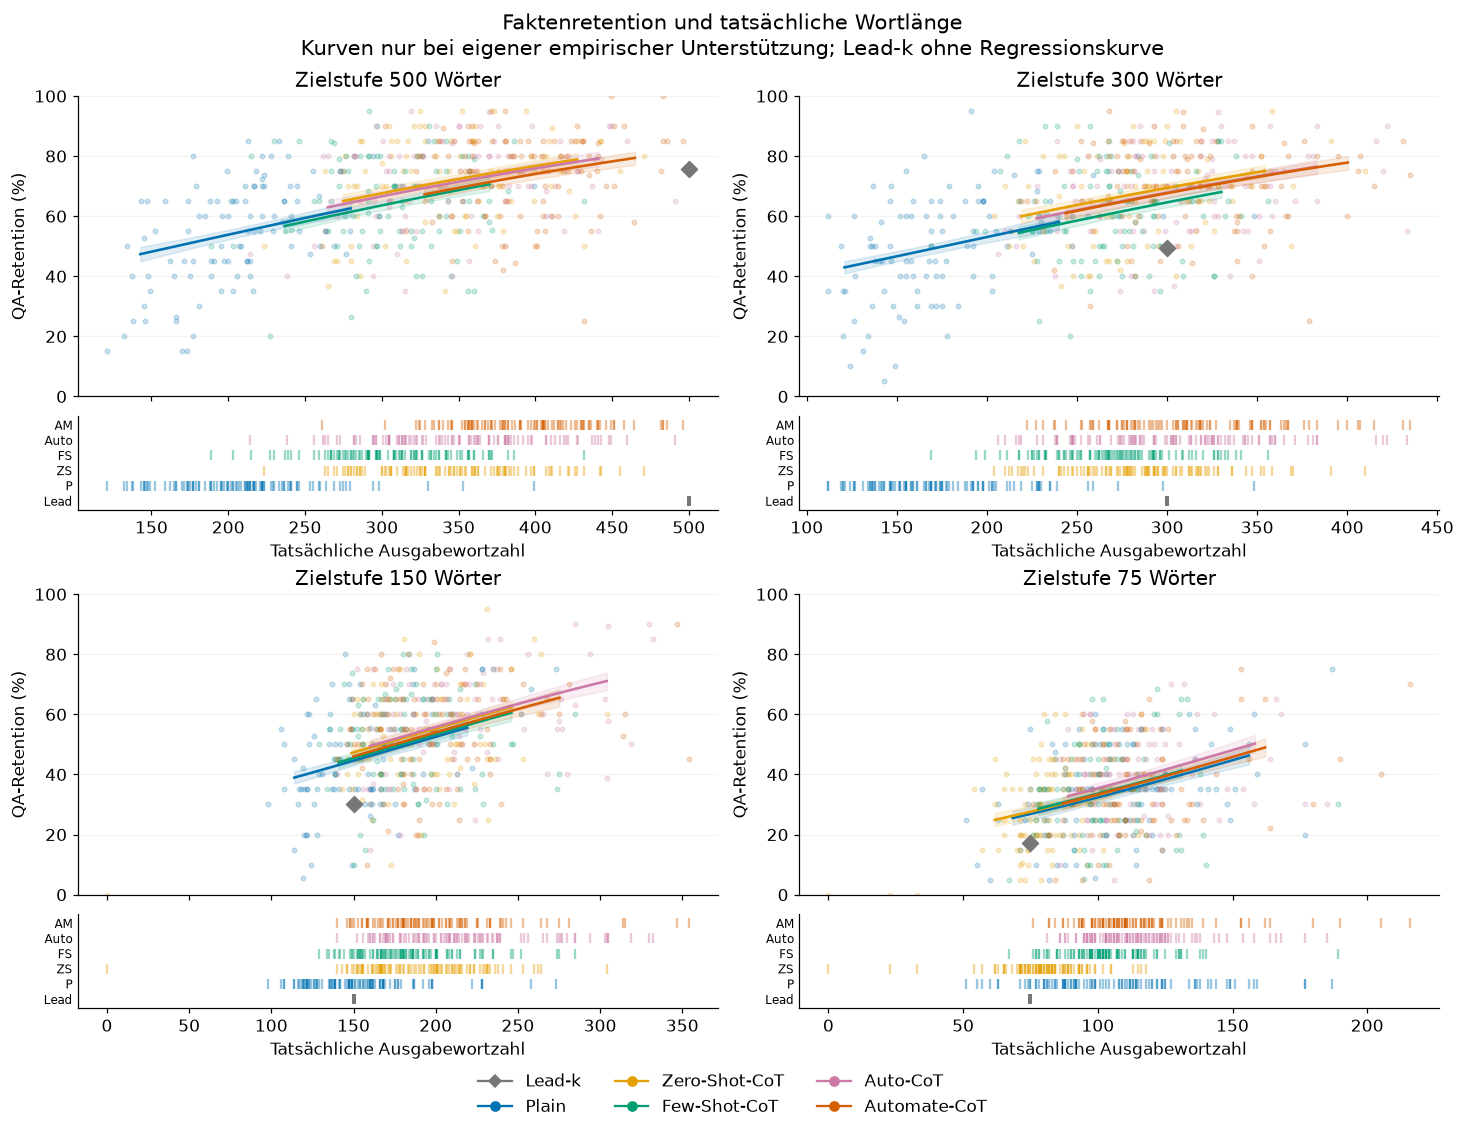

In [15]:
curve_rows=[]
state=models['linear']
for stage in STAGES:
    for method in GENERATIVE:
        actual=article[(article.method==method)&article.stage_target_words.eq(stage)].W
        lower,upper=actual.quantile([.05,.95])
        grid=np.linspace(lower,upper,70)
        ref=pd.DataFrame({'article_id':np.tile(IDS,len(grid)),'W':np.repeat(grid,len(IDS)),
                          'method':method,'stage_target_words':stage})
        X=design(ref,'linear')
        mu=expit(X@state['beta'])
        mean=mu.reshape(len(grid),len(IDS)).mean(axis=1)
        gradients=(X*(mu*(1-mu))[:,None]).reshape(len(grid),len(IDS),X.shape[1]).mean(axis=1)
        variance=np.einsum('ij,jk,ik->i',gradients,state['cov'],gradients)
        assert variance.min()>-1e-10
        se=np.sqrt(np.maximum(variance,0))/(mean*(1-mean))
        logit=np.log(mean/(1-mean))
        critical=student_t.ppf(.975,99)
        local=np.array([actual.sub(w).abs().le(max(5,.1*w)).sum()>=5 for w in grid])
        for w,p,low,high,ok in zip(grid,mean,expit(logit-critical*se),expit(logit+critical*se),local):
            curve_rows.append(dict(method=method,stage_target_words=stage,words=w,p=100*p,
                ci_low=100*low,ci_high=100*high,local_support=bool(ok)))
curves=pd.DataFrame(curve_rows)
export(curves,'abbildung_1_kurvenwerte_und_unterstuetzung')
fig=plt.figure(figsize=(13.2,10.2),layout='constrained')
gs=fig.add_gridspec(4,2,height_ratios=[3.2,1,3.2,1])
for index,stage in enumerate(STAGES):
    row,col=2*(index//2),index%2
    ax=fig.add_subplot(gs[row,col]);rug=fig.add_subplot(gs[row+1,col],sharex=ax)
    for mi,method in enumerate(METHODS):
        sub=article[(article.method==method)&article.stage_target_words.eq(stage)]
        color=METHOD_COLORS[method]
        if method=='lead_k':
            ax.scatter(sub.W.mean(),100*sub.retention_observed.mean(),marker='D',s=55,color=color,zorder=5)
        else:
            ax.scatter(sub.W,100*sub.retention_observed,s=9,alpha=.20,color=color)
            curve=curves[(curves.method==method)&curves.stage_target_words.eq(stage)]
            y=curve.p.where(curve.local_support)
            ax.plot(curve.words,y,color=color,lw=1.7)
            ax.fill_between(curve.words,curve.ci_low.where(curve.local_support),
                curve.ci_high.where(curve.local_support),color=color,alpha=.12)
        rug.scatter(sub.W,np.full(len(sub),mi),marker='|',s=45,alpha=.4,color=color)
    ax.set(ylim=(0,100),ylabel='QA-Retention (%)',title=f'Zielstufe {stage} Wörter')
    ax.tick_params(labelbottom=False)
    rug.set(yticks=range(6),yticklabels=['Lead','P','ZS','FS','Auto','AM'],xlabel='Tatsächliche Ausgabewortzahl',ylim=(-.6,5.6))
    rug.tick_params(axis='y',length=0,labelsize=8)
    ax.grid(axis='y',alpha=.15)
handles=[plt.Line2D([0],[0],color=METHOD_COLORS[m],marker='D' if m=='lead_k' else 'o',label=NAMES[m]) for m in METHODS]
fig.legend(handles=handles,loc='outside lower center',ncol=3,frameon=False)
fig.suptitle('Faktenretention und tatsächliche Wortlänge\nKurven nur bei eigener empirischer Unterstützung; Lead-k ohne Regressionskurve',fontsize=14)
savefig(fig,'01_faktenretention_und_tatsaechliche_wortlaenge')


### Ergänzende Grafiken: Welches Verfahren liegt bei gleicher Wortzahl höher?

Jede Abbildung vergleicht zwei Verfahren bei gleicher tatsächlicher Wortzahl. **Über null liegt das erstgenannte Verfahren höher, unter null das zweitgenannte.** Der Mittelwert wird über dieselben gestützten Artikel des jeweiligen Paars gebildet. Gezeichnet wird nur innerhalb des primären gemeinsamen Längenbereichs und mit mindestens fünf Beobachtungen je Verfahren in der Nachbarschaft (±max(5 Wörter, 10 %)). Fehlende Bereiche bleiben unterbrochen; nicht gestützte Stufen erhalten keine Kurve.

Die Bänder sind punktweise 95-%-Perzentilintervalle aus den vorhandenen 10.000 vollständigen Artikelbootstrap-Anpassungen des linearen binomialen Modells. Die Standardisierungsartikel werden in jeder Ziehung mit ihren Ziehhäufigkeiten gewichtet; der beobachtete Support bleibt fest. Ein Band über null stützt einen positiven Unterschied an dieser Stelle, ist aber kein simultaner Test über alle Wortzahlen. **Das Modell enthält keine Verfahren×Wortzahl-Interaktion:** Innerhalb einer Stufe kann die modellierte Rangfolge daher nicht mit der Wortzahl wechseln. Die Abbildungen zeigen die Größe und Unsicherheit des Unterschieds, keine neu geschätzte optimale Wortzahl.

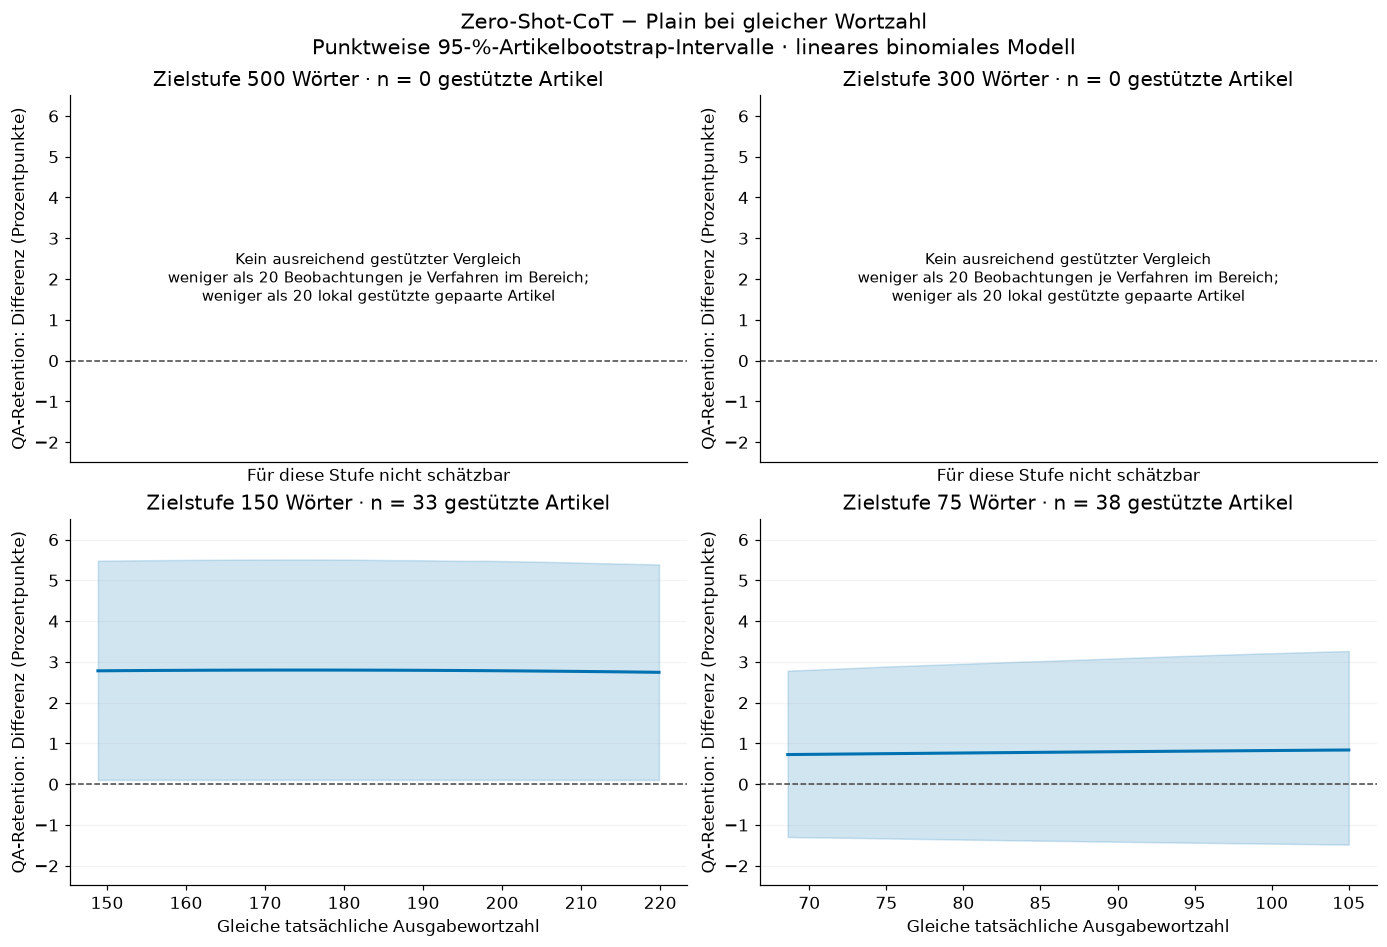

**Gezeigte Vergleichsbereiche:** Zielstufe 150: 149–220 tatsächliche Wörter (n=33); Zielstufe 75: 69–105 tatsächliche Wörter (n=38). Die Bereiche gelten jeweils für dieses Methodenpaar; daraus ergibt sich keine gemeinsame Rangfolge aller Verfahren.

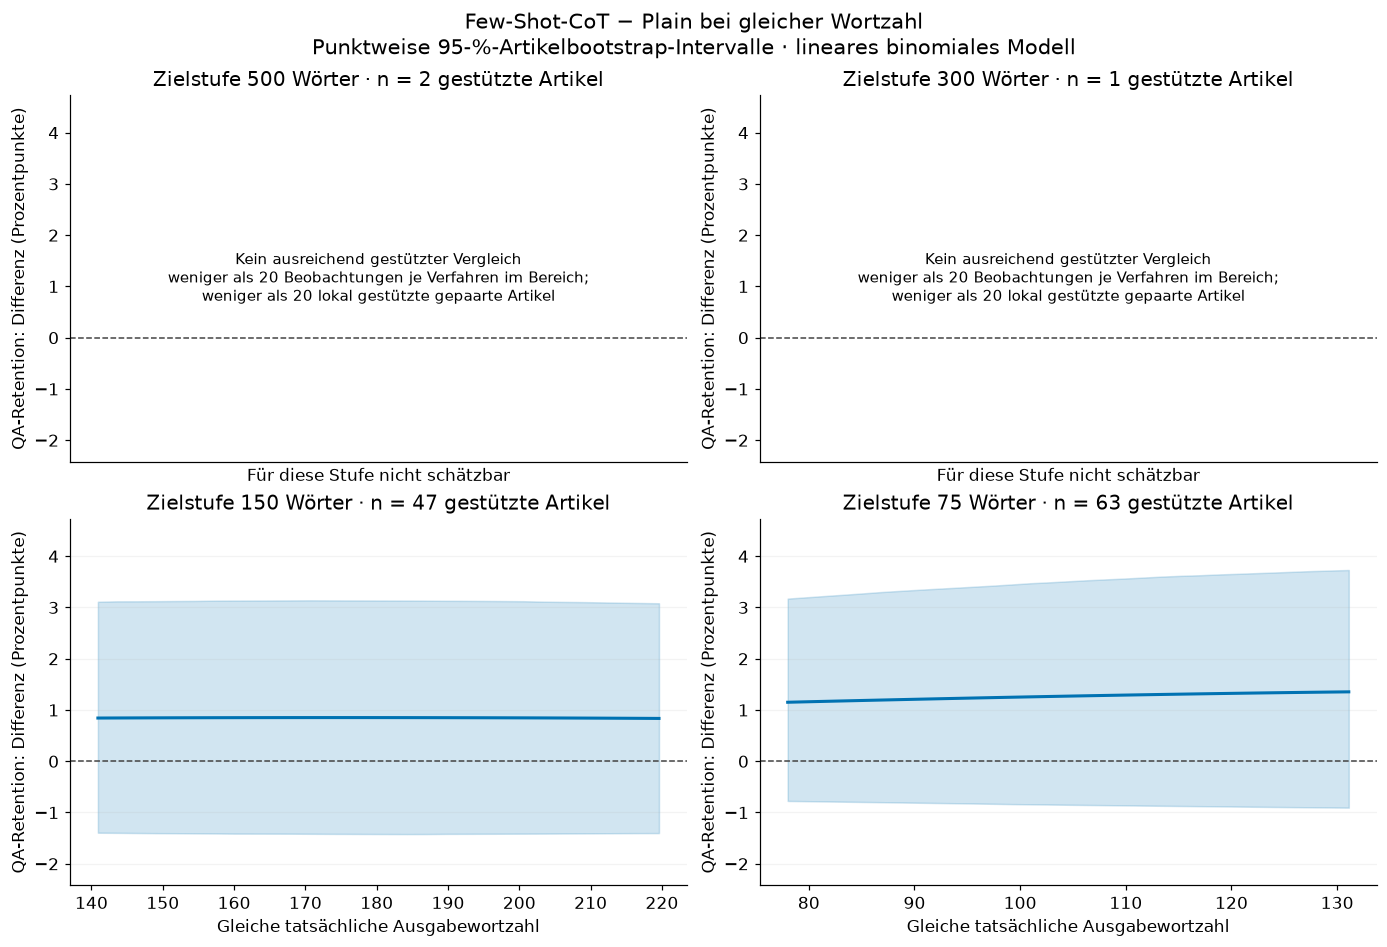

**Gezeigte Vergleichsbereiche:** Zielstufe 150: 141–220 tatsächliche Wörter (n=47); Zielstufe 75: 78–131 tatsächliche Wörter (n=63). Die Bereiche gelten jeweils für dieses Methodenpaar; daraus ergibt sich keine gemeinsame Rangfolge aller Verfahren.

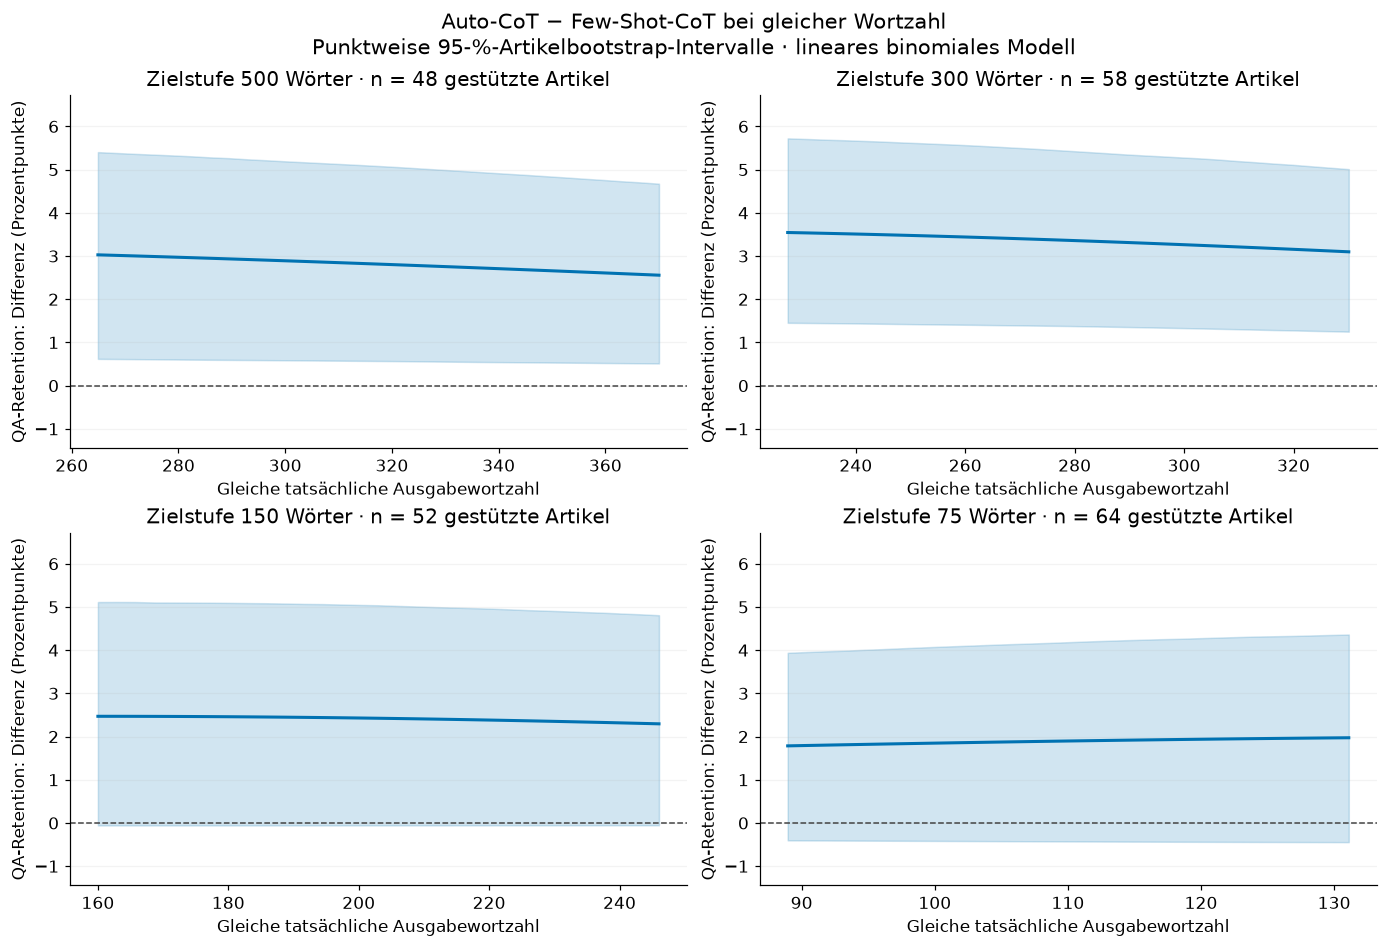

**Gezeigte Vergleichsbereiche:** Zielstufe 500: 265–370 tatsächliche Wörter (n=48); Zielstufe 300: 228–330 tatsächliche Wörter (n=58); Zielstufe 150: 160–246 tatsächliche Wörter (n=52); Zielstufe 75: 89–131 tatsächliche Wörter (n=64). Die Bereiche gelten jeweils für dieses Methodenpaar; daraus ergibt sich keine gemeinsame Rangfolge aller Verfahren.

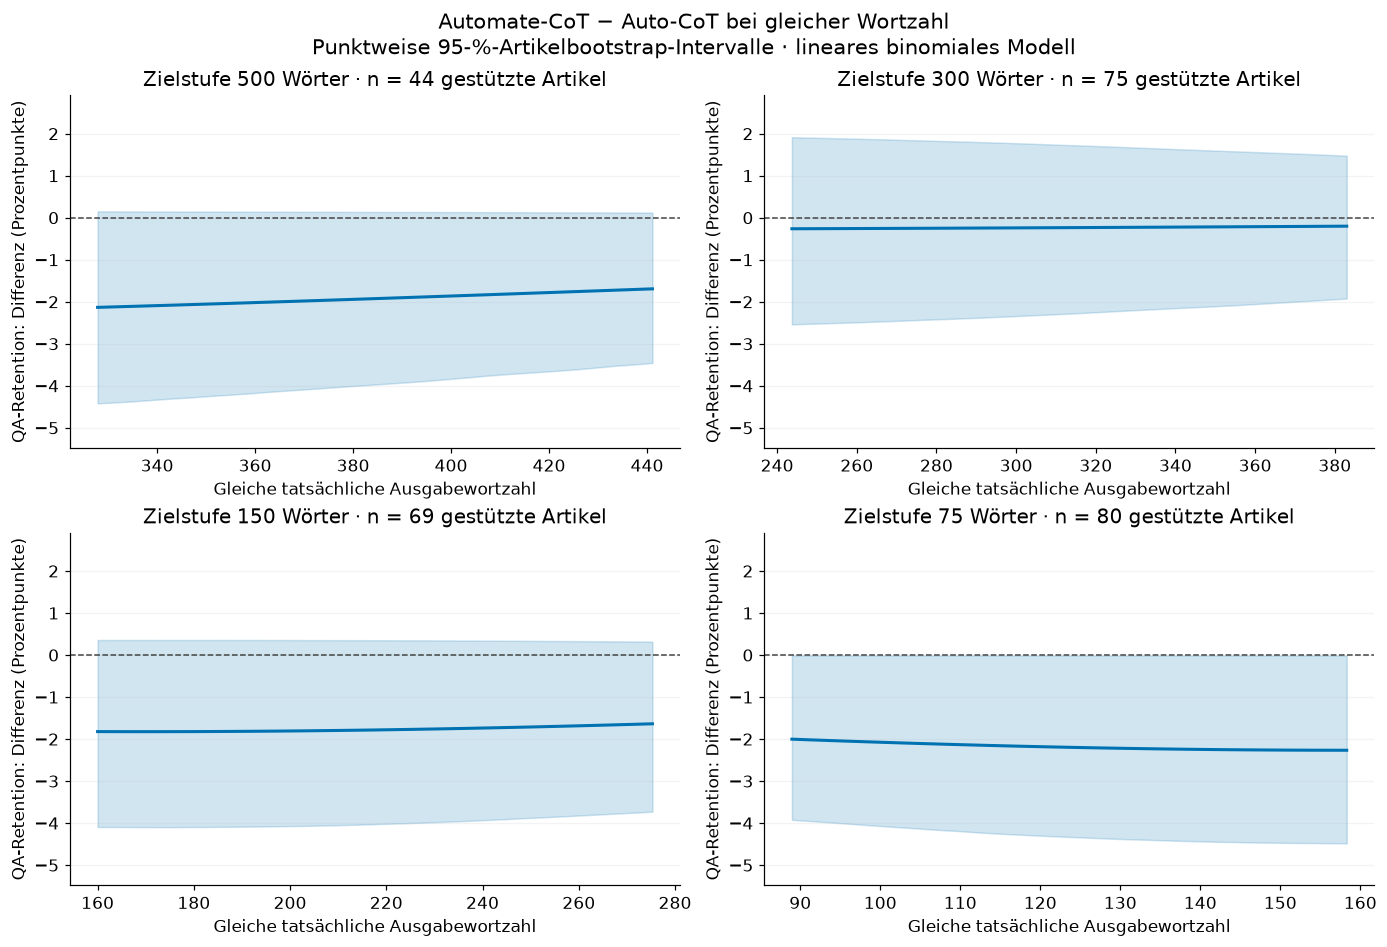

**Gezeigte Vergleichsbereiche:** Zielstufe 500: 328–441 tatsächliche Wörter (n=44); Zielstufe 300: 244–383 tatsächliche Wörter (n=75); Zielstufe 150: 160–275 tatsächliche Wörter (n=69); Zielstufe 75: 89–158 tatsächliche Wörter (n=80). Die Bereiche gelten jeweils für dieses Methodenpaar; daraus ergibt sich keine gemeinsame Rangfolge aller Verfahren.

In [16]:
word_contrast_rows=[]
for contrast_index,(first,second) in enumerate(CONTRASTS,1):
    fig,axes=plt.subplots(2,2,figsize=(12.5,8.5),layout='constrained')
    for ax,stage in zip(axes.flat,STAGES):
        support=get_support(first,second,stage)
        ax.axhline(0,color='#444444',ls='--',lw=1)
        ax.set(xlabel='Gleiche tatsächliche Ausgabewortzahl',ylabel='QA-Retention: Differenz (Prozentpunkte)',
               title=f'Zielstufe {stage} Wörter · n = {support["n_supported"]} gestützte Artikel')
        if not support['estimable']:
            ax.set(xticks=[],xlabel='Für diese Stufe nicht schätzbar')
            ax.text(.5,.5,'Kein ausreichend gestützter Vergleich\n'+support['reason'].replace('; ',';\n'),
                    transform=ax.transAxes,ha='center',va='center',fontsize=10)
            word_contrast_rows.append(dict(first=first,second=second,stage_target_words=stage,
                words=np.nan,n_articles=support['n_supported'],local_support=False,status=support['reason']))
            continue
        ids=support['ids']; ai=np.array([article_map[a] for a in ids])
        grid=np.linspace(support['lower'],support['upper'],31)
        coef=boot_coefficients['linear']
        weights=bootstrap_counts[:,ai]
        denominator=weights.sum(axis=1)
        article_effect=np.zeros((len(coef),len(ids)))
        for j,index in enumerate(ai):
            if index:
                article_effect[:,j]=coef[:,20+index-1]
        ci_a=cell_map[(first,stage)];ci_b=cell_map[(second,stage)]
        length_index=119+STAGES.index(stage)
        plotted=[]
        for w in grid:
            local_n=[int(model_data.loc[model_data.method.eq(m)&model_data.stage_target_words.eq(stage),'W']
                         .sub(w).abs().le(max(5,.1*w)).sum()) for m in [first,second]]
            local=min(local_n)>=5
            row=dict(first=first,second=second,stage_target_words=stage,words=w,n_articles=len(ids),
                n_local_first=local_n[0],n_local_second=local_n[1],local_support=local,
                difference_pp=np.nan,ci_low_pp=np.nan,ci_high_pp=np.nan,n_bootstrap_valid=0,status='zu wenig lokaler Support')
            if local:
                ref=pd.DataFrame({'article_id':ids,'method':first,'stage_target_words':stage,'W':w})
                xa=design(ref,'linear');xb=design(ref.assign(method=second),'linear')
                beta=models['linear']['beta']
                point=100*np.mean(expit(xa@beta)-expit(xb@beta))
                offset=(w-stage)/100
                pa=expit(article_effect+coef[:,ci_a,None]+offset*coef[:,length_index,None])
                pb=expit(article_effect+coef[:,ci_b,None]+offset*coef[:,length_index,None])
                samples=np.divide(100*((pa-pb)*weights).sum(axis=1),denominator,
                    out=np.full(len(coef),np.nan),where=denominator>0)
                valid=np.isfinite(samples)
                reliable=int(valid.sum())>=int(.99*B)
                if reliable:
                    low,high=np.quantile(samples[valid],[.025,.975])
                    row.update(difference_pp=point,ci_low_pp=low,ci_high_pp=high,
                               n_bootstrap_valid=int(valid.sum()),status='gestützter punktweiser Vergleich')
                # Unabhängige Kontrolle der optimierten Berechnung gegen die Modellmatrix.
                assert np.allclose(pa[:3],expit(coef[:3]@xa.T),rtol=0,atol=1e-12,equal_nan=True)
                assert np.allclose(pb[:3],expit(coef[:3]@xb.T),rtol=0,atol=1e-12,equal_nan=True)
            plotted.append(row);word_contrast_rows.append(row)
        values=pd.DataFrame(plotted)
        ax.plot(values.words,values.difference_pp,color='#0072B2',lw=2)
        ax.fill_between(values.words,values.ci_low_pp,values.ci_high_pp,color='#0072B2',alpha=.18)
        ax.grid(axis='y',alpha=.15)
    # Gleiche Skala innerhalb eines Vergleichs, mit sichtbarer Nulllinie.
    own=[r for r in word_contrast_rows if r['first']==first and r['second']==second and pd.notna(r.get('difference_pp'))]
    if own:
        lo=min(0,min(r['ci_low_pp'] for r in own));hi=max(0,max(r['ci_high_pp'] for r in own))
        pad=max(1,.08*(hi-lo))
        for ax in axes.flat: ax.set_ylim(lo-pad,hi+pad)
    fig.suptitle(f'{NAMES[first]} − {NAMES[second]} bei gleicher Wortzahl\n'
                 'Punktweise 95-%-Artikelbootstrap-Intervalle · lineares binomiales Modell',fontsize=14)
    savefig(fig,f'05{contrast_index}_wortzahlabhaengiger_kontrast_{first}_vs_{second}')
    ranges=[]
    for stage in STAGES:
        valid_rows=[r for r in own if r['stage_target_words']==stage]
        if valid_rows:
            ranges.append(f"Zielstufe {stage}: {min(r['words'] for r in valid_rows):.0f}–{max(r['words'] for r in valid_rows):.0f} tatsächliche Wörter (n={valid_rows[0]['n_articles']})")
    display(Markdown('**Gezeigte Vergleichsbereiche:** '+('; '.join(ranges) if ranges else 'Kein gestützter Bereich')+
        '. Die Bereiche gelten jeweils für dieses Methodenpaar; daraus ergibt sich keine gemeinsame Rangfolge aller Verfahren.'))
export(pd.DataFrame(word_contrast_rows),'grafik_wortzahlabhaengige_kontraste_95ci')


### Abbildung 2: originale und längenkontrollierte Kontraste

Grau: Originalanalyse aller 100 Artikel. Blau: primäres lineares Modell innerhalb
des gestützten Vergleichsbereichs. Die Populationen unterscheiden sich; die zusätzliche
Spalte `raw_same_articles_pp` in der Ergebnistabelle zeigt die unmodellierte Differenz
auf genau den ausgewählten Artikeln. Die rechte Spalte markiert nicht zuverlässig
schätzbare Vergleiche sowie die Zahl unterstützender Artikel.

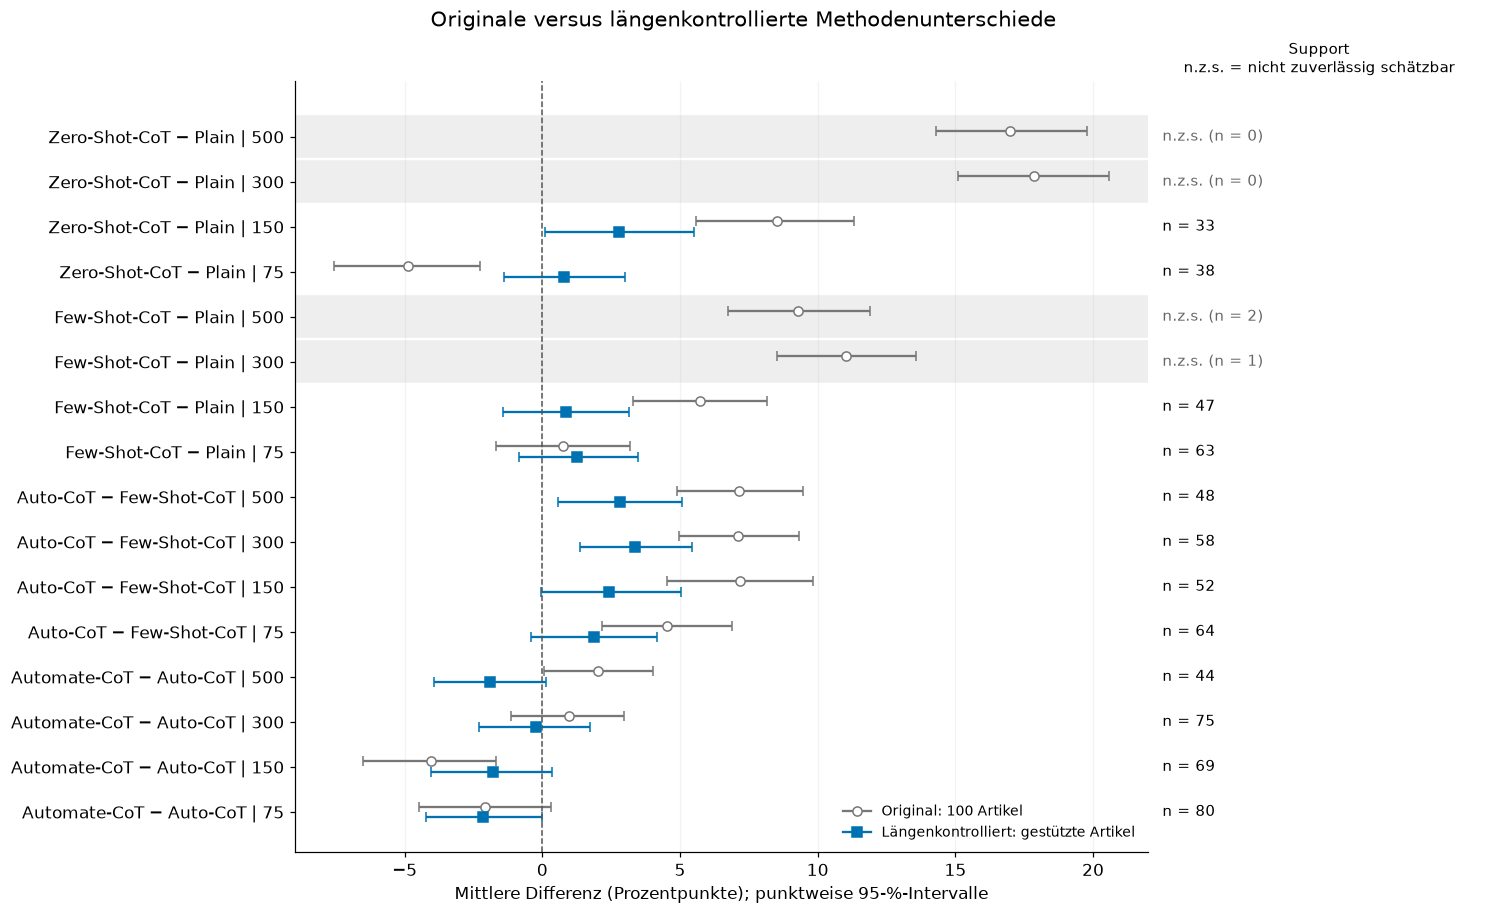

In [17]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(13.4,8.2),sharey=True,
    gridspec_kw={'width_ratios':[3.4,1.25]},layout='constrained')
for y,row in enumerate(core_table.itertuples()):
    ax.errorbar(row.original_difference_pp,y-.12,
        xerr=[[row.original_difference_pp-row.original_ci_low_pp],[row.original_ci_high_pp-row.original_difference_pp]],
        fmt='o',color='#777777',mfc='white',capsize=3)
    if row.reliable:
        ax.errorbar(row.controlled_difference_pp,y+.12,
            xerr=[[row.controlled_difference_pp-row.controlled_ci_low_pp],[row.controlled_ci_high_pp-row.controlled_difference_pp]],
            fmt='s',color='#0072B2',capsize=3)
        bx.text(0,y,f'n = {row.n_supported_articles}'+(' (klein)' if row.n_supported_articles<30 else ''),va='center',fontsize=10)
    else:
        ax.axhspan(y-.45,y+.45,color='#EEEEEE',zorder=-2)
        bx.text(0,y,f'n.z.s. (n = {row.n_supported_articles})',va='center',fontsize=10,color='#666666')
ax.axvline(0,color='#555555',ls='--',lw=1)
ax.set(yticks=range(16),yticklabels=[f'{r.contrast} | {r.stage_target_words}' for r in core_table.itertuples()],
    xlabel='Mittlere Differenz (Prozentpunkte); punktweise 95-%-Intervalle')
ax.invert_yaxis();ax.grid(axis='x',alpha=.15)
bx.set(xlim=(0,1),xticks=[]);bx.tick_params(left=False,labelleft=False)
for spine in bx.spines.values():spine.set_visible(False)
ax.legend(handles=[plt.Line2D([0],[0],marker='o',mfc='white',color='#777777',label='Original: 100 Artikel'),
    plt.Line2D([0],[0],marker='s',color='#0072B2',label='Längenkontrolliert: gestützte Artikel')],loc='lower right',frameon=False,fontsize=9)
bx.set_title('Support\nn.z.s. = nicht zuverlässig schätzbar',fontsize=10)
fig.suptitle('Originale versus längenkontrollierte Methodenunterschiede',fontsize=14)
savefig(fig,'02_originale_und_laengenkontrollierte_kontraste')


## 8. Analyse E: Modellsensitivität

Verglichen werden linearer Längeneffekt und natürlicher Spline sowie drei
Überlappungsdefinitionen. Die bisherigen direkten ±5-%-Artikelpaarungen werden
vollständig reproduziert, einschließlich ihrer 10.000 Artikelpaar-Bootstrap-Intervalle
und deterministischen Teilstrom-Seeds. Kleine direkte Paarstichproben bleiben als
solche sichtbar und werden nicht als Nachweis eines stabilen Effekts interpretiert.

Direkte Paarungen und Modellstandardisierung haben unterschiedliche Längenkriterien
und Artikelmengen. Unterschiede ihrer Werte sind daher keine reine Modellprüfung.
Die hier ergänzte Rohdifferenz auf der Standardisierungsstichprobe hilft, diese
Selektionswirkung sichtbar zu halten.

In [18]:
direct_rows=[]
for stage in STAGES:
    for i,j in combinations(range(6),2):
        first,second=METHODS[i],METHODS[j]
        left=article[(article.method==first)&article.stage_target_words.eq(stage)].set_index('article_id').loc[IDS]
        right=article[(article.method==second)&article.stage_target_words.eq(stage)].set_index('article_id').loc[IDS]
        selected=(left.W+right.W).gt(0)&(40*(left.W-right.W).abs()).le(left.W+right.W)
        differences=(100*(left.retention_observed-right.retention_observed))[selected].to_numpy()
        n=len(differences)
        lo=hi=mean=np.nan
        if n:mean=float(differences.mean())
        if n>=2:
            rng=np.random.default_rng(np.random.SeedSequence([SEED,stage,i,j]))
            means=differences[rng.integers(0,n,size=(B,n))].mean(axis=1)
            lo,hi=np.quantile(means,[.025,.975],method='linear')
        direct_rows.append(dict(first=first,second=second,stage_target_words=stage,n=n,
            mean_delta_pp=mean,ci95_low_pp=lo,ci95_high_pp=hi))
direct=pd.DataFrame(direct_rows)
direct_archive=pd.read_csv(MATCHED/'bootstrap_intervalle_60_eindeutige_vergleiche.csv')
direct_check=direct.merge(direct_archive.rename(columns={'row_method':'first','column_method':'second'}),
    on=['first','second','stage_target_words'],suffixes=('','_old'),validate='one_to_one')
assert direct_check.n.eq(direct_check.n_old).all()
for field in ['mean_delta_pp','ci95_low_pp','ci95_high_pp']:
    assert np.allclose(direct_check[field],direct_check[field+'_old'],rtol=0,atol=1e-12,equal_nan=True),field
export(direct,'E_reproduzierte_direkte_5prozent_paarungen')
direct_model_rows=[]
for r in core_table.itertuples():
    selected=direct[(direct['first']==r.first)&(direct.second==r.second)&direct.stage_target_words.eq(r.stage_target_words)]
    orientation=1
    if selected.empty:
        selected=direct[(direct['first']==r.second)&(direct.second==r.first)&direct.stage_target_words.eq(r.stage_target_words)]
        orientation=-1
    d=selected.iloc[0]
    direct_mean=orientation*d.mean_delta_pp
    direct_low=d.ci95_low_pp if orientation==1 else -d.ci95_high_pp
    direct_high=d.ci95_high_pp if orientation==1 else -d.ci95_low_pp
    direct_model_rows.append(dict(contrast=r.contrast,stage_target_words=r.stage_target_words,
        model_difference_pp=r.controlled_difference_pp,model_ci_low_pp=r.controlled_ci_low_pp,
        model_ci_high_pp=r.controlled_ci_high_pp,model_n_articles=r.n_supported_articles,model_reliable=r.reliable,
        raw_on_model_support_pp=r.raw_same_articles_pp,direct_5pct_difference_pp=direct_mean,
        direct_5pct_ci_low_pp=direct_low,direct_5pct_ci_high_pp=direct_high,direct_5pct_n=int(d.n),
        direct_5pct_small_below10=bool(0<d.n<10),
        same_point_direction=bool(direct_mean*r.controlled_difference_pp>0)
            if pd.notna(direct_mean) and pd.notna(r.controlled_difference_pp) else np.nan))
direct_model=pd.DataFrame(direct_model_rows)
export(direct_model,'E_modell_gegen_direkte_5prozent_paarung_16_kontraste')
display(direct_model.round(3))
sensitivity_rows=[]
for first,second in CONTRASTS:
    for stage in STAGES:
        for definition in SUPPORT_DEFS:
            support=get_support(first,second,stage,definition)
            for kind in models:
                result=oriented_result(first,second,stage,definition,kind)
                sensitivity_rows.append(dict(first=first,second=second,stage_target_words=stage,
                    definition=definition,model=kind,n=support['n_supported'],
                    reliable=result is not None and bool(result.reliable),
                    difference_pp=result.adjusted_difference_pp if result is not None else np.nan,
                    ci_low_pp=result.ci_low_pp if result is not None else np.nan,
                    ci_high_pp=result.ci_high_pp if result is not None else np.nan))
sensitivity=pd.DataFrame(sensitivity_rows)
export(sensitivity,'E_sensitivitaet_16_kontraste_modelle_und_support')
model_sensitivity=core_table[['first','second','stage_target_words','controlled_difference_pp']].copy()
flex=[]
for row in model_sensitivity.itertuples():
    result=oriented_result(row.first,row.second,row.stage_target_words,kind='spline')
    flex.append(result.adjusted_difference_pp if result is not None else np.nan)
model_sensitivity['spline_difference_pp']=flex
model_sensitivity['spline_minus_linear_pp']=model_sensitivity.spline_difference_pp-model_sensitivity.controlled_difference_pp
model_sensitivity['model_sign_change']=(model_sensitivity.spline_difference_pp*model_sensitivity.controlled_difference_pp)<0
export(model_sensitivity,'E_linear_gegen_spline_prim_support')
display(model_sensitivity.round(3))
comparable=model_sensitivity.dropna(subset=['controlled_difference_pp','spline_difference_pp'])
display(Markdown(f'Die flexible Form ändert {int(comparable.model_sign_change.sum())}/{len(comparable)} '
    'gestützte Kontrastvorzeichen gegenüber der linearen Form. Dies wird als Formunsicherheit '
    'ausgewiesen; ein kleineres Residualmaß allein ersetzt keine inhaltliche oder unabhängige Validierung.'))
display(sensitivity.pivot(index=['first','second','stage_target_words'],columns=['definition','model'],values='difference_pp').round(3))
display(Markdown('**Keine automatische Modellselektion:** Die dokumentierten Unterschiede in Devianz, '
    'numerischer Stabilität und standardisierten Effekten dienen der Formdiagnostik. '
    'Das lineare Hauptmodell bleibt unabhängig davon bestehen, welches Verfahren dadurch günstiger erscheint.'))


,contrast,stage_target_words,model_difference_pp,model_ci_low_pp,model_ci_high_pp,model_n_articles,model_reliable,raw_on_model_support_pp,direct_5pct_difference_pp,direct_5pct_ci_low_pp,direct_5pct_ci_high_pp,direct_5pct_n,direct_5pct_small_below10,same_point_direction
0,Zero-Shot-CoT − Plain,500,NaN,NaN,NaN,0,False,NaN,-5.000,NaN,NaN,1,True,NaN
1,Zero-Shot-CoT − Plain,300,NaN,NaN,NaN,0,False,NaN,-2.500,-5.000,-0.000,2,True,NaN
2,Zero-Shot-CoT − Plain,150,2.799,0.106,5.513,33,True,5.262,3.567,-3.275,11.345,9,True,True
3,Zero-Shot-CoT − Plain,75,0.779,-1.381,3.017,38,True,-1.171,0.000,-3.750,3.750,8,True,True
4,Few-Shot-CoT − Plain,500,NaN,NaN,NaN,2,False,NaN,7.602,2.500,11.491,4,True,NaN
5,Few-Shot-CoT − Plain,300,NaN,NaN,NaN,1,False,NaN,2.383,-12.171,13.158,4,True,NaN
6,Few-Shot-CoT − Plain,150,0.849,-1.411,3.134,47,True,4.269,-0.670,-5.470,4.229,13,False,False
7,Few-Shot-CoT − Plain,75,1.255,-0.840,3.461,63,True,1.416,2.314,-2.019,6.981,15,False,True
8,Auto-CoT − Few-Shot-CoT,500,2.821,0.568,5.085,48,True,4.797,1.858,-2.211,5.519,15,False,True
9,Auto-CoT − Few-Shot-CoT,300,3.369,1.377,5.444,58,True,7.067,3.911,-0.012,7.847,22,False,True


,first,second,stage_target_words,controlled_difference_pp,spline_difference_pp,spline_minus_linear_pp,model_sign_change
0,zero_shot_cot,plain,500,NaN,NaN,NaN,False
1,zero_shot_cot,plain,300,NaN,NaN,NaN,False
2,zero_shot_cot,plain,150,2.799,2.077,-0.722,False
3,zero_shot_cot,plain,75,0.779,1.546,0.767,False
4,few_shot_cot,plain,500,NaN,NaN,NaN,False
5,few_shot_cot,plain,300,NaN,NaN,NaN,False
6,few_shot_cot,plain,150,0.849,-0.282,-1.131,True
7,few_shot_cot,plain,75,1.255,0.196,-1.059,False
8,auto_cot,few_shot_cot,500,2.821,3.439,0.618,False
9,auto_cot,few_shot_cot,300,3.369,3.782,0.413,False


Die flexible Form ändert 1/12 gestützte Kontrastvorzeichen gegenüber der linearen Form. Dies wird als Formunsicherheit ausgewiesen; ein kleineres Residualmaß allein ersetzt keine inhaltliche oder unabhängige Validierung.

definition                                    central95         broad         \
model                                            linear spline linear spline   
first         second       stage_target_words                                  
auto_cot      few_shot_cot 75                     1.882  2.168  1.879  2.161   
                           150                    2.419  2.885  2.415  2.878   
                           300                    3.369  3.782  3.364  3.782   
                           500                    2.821  3.439  2.875  3.516   
automate_cot  auto_cot     75                    -2.150 -2.209 -2.136 -2.196   
                           150                   -1.797 -2.131 -1.790 -2.121   
                           300                   -0.240 -0.150 -0.240 -0.151   
                           500                   -1.912 -1.207 -1.905 -1.198   
few_shot_cot  plain        75                     1.255  0.196  1.247  0.194   
                           150                    0.849 -0.282  0.854 -0.284   
                           300                      NaN    NaN    NaN    NaN   
                           500                      NaN    NaN    NaN    NaN   
zero_shot_cot plain        75                     0.779  1.546  0.779  1.548   
                           150                    2.799  2.077  2.804  2.079   
                           300                      NaN    NaN    NaN    NaN   
                           500                      NaN    NaN    NaN    NaN   

definition                                    central80         
model                                            linear spline  
first         second       stage_target_words                   
auto_cot      few_shot_cot 75                     1.882  2.169  
                           150                    2.422  2.884  
                           300                    3.360  3.767  
                           500                    2.871  3.493  
automate_cot  auto_cot     75                    -2.170 -2.231  
                           150                   -1.798 -2.130  
                           300                   -0.242 -0.151  
                           500                   -1.935 -1.221  
few_shot_cot  plain        75                     1.256  0.197  
                           150                    0.850 -0.283  
                           300                      NaN    NaN  
                           500                      NaN    NaN  
zero_shot_cot plain        75                     0.776  1.546  
                           150                      NaN    NaN  
                           300                      NaN    NaN  
                           500                      NaN    NaN

**Keine automatische Modellselektion:** Die dokumentierten Unterschiede in Devianz, numerischer Stabilität und standardisierten Effekten dienen der Formdiagnostik. Das lineare Hauptmodell bleibt unabhängig davon bestehen, welches Verfahren dadurch günstiger erscheint.

## 9. Analyse F: Rangfolgen und Forschungsfragen

Eine vollständige modellbasierte Rangfolge setzt eine gemeinsame gestützte
Standardisierung aller fünf generativen Verfahren voraus. Paarweise gestützte
Kontraste auf unterschiedlichen Artikelmengen werden **nicht** zu einer Rangliste
zusammengesetzt. Die Originalrangfolge und die vorhandene heuristische Adjustierung
werden unverändert nebeneinander gezeigt; Lead-k bleibt deskriptiv enthalten.

In [19]:
rank_comparison=original_ranks.copy()
rank_comparison['model_based_rank']=np.nan
rank_comparison['model_rank_status']='keine ausreichend gestützte gemeinsame Fünfmethoden-Standardisierung'
global_rows=[]
for stage,support in global_support.items():
    global_rows.append(dict(stage_target_words=stage,common_lower=support['lower'],common_upper=support['upper'],
        n_supported=support['n_supported'],estimable=support['estimable'],status=support['reason']))
    if support['estimable']:
        # Alle Verfahren auf identischem empirischem Artikel-Wortzahl-Panel standardisieren.
        ids=support['ids']
        observed=article[article.stage_target_words.eq(stage)&article.method.isin(GENERATIVE)&article.article_id.isin(ids)]
        reference=observed[['article_id','W','stage_target_words']].copy()
        values=[]
        for method in GENERATIVE:
            values.append(expit(design(reference.assign(method=method),'linear')@models['linear']['beta']).mean())
        ranks=rank_scores(np.asarray(values),tol=1e-12)
        for method,rank in zip(GENERATIVE,ranks):
            mask=rank_comparison.method.eq(method)&rank_comparison.stage_target_words.eq(stage)
            rank_comparison.loc[mask,'model_based_rank']=int(rank)
            rank_comparison.loc[mask,'model_rank_status']='gemeinsam standardisiert, generative Verfahren'
export(rank_comparison,'F_originale_heuristische_und_zulaessige_modellraenge')
export(pd.DataFrame(global_rows),'F_gemeinsamer_fuenfmethoden_support')
display(rank_comparison[['method','stage_target_words','original_rank_raw','original_rank_adjusted','model_based_rank','model_rank_status']])

auto_rows=[]
for other in GENERATIVE:
    if other=='auto_cot':continue
    support=get_support('auto_cot',other,75)
    result=oriented_result('auto_cot',other,75)
    auto_rows.append(dict(comparison='Auto-CoT − '+NAMES[other],n_articles=support['n_supported'],
        reliable=result is not None and bool(result.reliable),difference_pp=result.adjusted_difference_pp if result is not None else np.nan,
        ci_low_pp=result.ci_low_pp if result is not None else np.nan,
        ci_high_pp=result.ci_high_pp if result is not None else np.nan,status=support['reason']))
auto75=pd.DataFrame(auto_rows)
export(auto75,'F_auto_cot_75_gegen_alle_generativen_verfahren')
display(auto75.round(3))
auto_sensitivity_rows=[]
for other in GENERATIVE:
    if other=='auto_cot':continue
    for definition in SUPPORT_DEFS:
        for kind in models:
            result=oriented_result('auto_cot',other,75,definition,kind)
            support=get_support('auto_cot',other,75,definition)
            auto_sensitivity_rows.append(dict(comparison='Auto-CoT − '+NAMES[other],definition=definition,
                model=kind,n_articles=support['n_supported'],reliable=result is not None and bool(result.reliable),
                difference_pp=result.adjusted_difference_pp if result is not None else np.nan,
                ci_low_pp=result.ci_low_pp if result is not None else np.nan,
                ci_high_pp=result.ci_high_pp if result is not None else np.nan))
auto_sensitivity=pd.DataFrame(auto_sensitivity_rows)
export(auto_sensitivity,'F_auto_cot_75_support_und_modellsensitivitaet')
display(auto_sensitivity[auto_sensitivity.comparison.eq('Auto-CoT − Zero-Shot-CoT')].round(3))
display(Markdown('**Einordnung der 75-Wörter-Frage:** Für Auto-CoT gegenüber Plain bleiben die '
    'modellierten Unterschiede positiv; die vollständigen Modell-/Supportvarianten sind exportiert. '
    'Der Vergleich zu Few-Shot-CoT überdeckt im primären Intervall null. Die Intervallgrenze zu '
    'Automate-CoT liegt sehr nahe null und ist explorativ zu lesen. Zu Zero-Shot-CoT reicht der '
    'primäre gepaarte Support nicht aus; auch die berechenbare breitere Variante ist keine '
    'Bestätigung einer generellen Überlegenheit.'))

research_questions=[]
for first,second,stages in [('zero_shot_cot','plain',[500,300]),('automate_cot','auto_cot',STAGES)]:
    for stage in stages:
        row=core_table[(core_table['first']==first)&(core_table.second==second)&core_table.stage_target_words.eq(stage)].iloc[0]
        research_questions.append(dict(question=f'{NAMES[first]} − {NAMES[second]} bei {stage}',
            original_pp=row.original_difference_pp,controlled_pp=row.controlled_difference_pp,
            ci_low_pp=row.controlled_ci_low_pp,ci_high_pp=row.controlled_ci_high_pp,status=row.status))
export(pd.DataFrame(research_questions),'F_antworten_auf_zentrale_methodenfragen')
display(pd.DataFrame(research_questions).round(3))


,method,stage_target_words,original_rank_raw,original_rank_adjusted,model_based_rank,model_rank_status
0,lead_k,500,1,1,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
1,lead_k,300,6,5,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
2,lead_k,150,6,6,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
3,lead_k,75,6,6,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
4,plain,500,6,6,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
5,plain,300,5,6,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
6,plain,150,5,5,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
7,plain,75,4,5,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
8,zero_shot_cot,500,3,3,NaN,keine ausreichend gestützte gemeinsame Fünfmet...
9,zero_shot_cot,300,3,2,NaN,keine ausreichend gestützte gemeinsame Fünfmet...


,comparison,n_articles,reliable,difference_pp,ci_low_pp,ci_high_pp,status
0,Auto-CoT − Plain,59,True,3.187,1.356,5.040,gestützter explorativer Vergleich
1,Auto-CoT − Zero-Shot-CoT,8,False,NaN,NaN,NaN,weniger als 20 lokal gestützte gepaarte Artikel
2,Auto-CoT − Few-Shot-CoT,64,True,1.882,-0.423,4.153,gestützter explorativer Vergleich
3,Auto-CoT − Automate-CoT,80,True,2.150,0.011,4.229,gestützter explorativer Vergleich


,comparison,definition,model,n_articles,reliable,difference_pp,ci_low_pp,ci_high_pp
6,Auto-CoT − Zero-Shot-CoT,central95,linear,8,False,NaN,NaN,NaN
7,Auto-CoT − Zero-Shot-CoT,central95,spline,8,False,NaN,NaN,NaN
8,Auto-CoT − Zero-Shot-CoT,broad,linear,30,True,2.261,-0.150,4.652
9,Auto-CoT − Zero-Shot-CoT,broad,spline,30,True,0.637,-2.033,3.252
10,Auto-CoT − Zero-Shot-CoT,central80,linear,0,False,NaN,NaN,NaN
11,Auto-CoT − Zero-Shot-CoT,central80,spline,0,False,NaN,NaN,NaN


**Einordnung der 75-Wörter-Frage:** Für Auto-CoT gegenüber Plain bleiben die modellierten Unterschiede positiv; die vollständigen Modell-/Supportvarianten sind exportiert. Der Vergleich zu Few-Shot-CoT überdeckt im primären Intervall null. Die Intervallgrenze zu Automate-CoT liegt sehr nahe null und ist explorativ zu lesen. Zu Zero-Shot-CoT reicht der primäre gepaarte Support nicht aus; auch die berechenbare breitere Variante ist keine Bestätigung einer generellen Überlegenheit.

,question,original_pp,controlled_pp,ci_low_pp,ci_high_pp,status
0,Zero-Shot-CoT − Plain bei 500,16.997,NaN,NaN,NaN,nicht zuverlässig schätzbar: weniger als 20 Be...
1,Zero-Shot-CoT − Plain bei 300,17.843,NaN,NaN,NaN,nicht zuverlässig schätzbar: weniger als 20 Be...
2,Automate-CoT − Auto-CoT bei 500,2.039,-1.912,-3.945,0.135,gestützt
3,Automate-CoT − Auto-CoT bei 300,0.956,-0.240,-2.309,1.748,gestützt
4,Automate-CoT − Auto-CoT bei 150,-4.051,-1.797,-4.047,0.355,gestützt
5,Automate-CoT − Auto-CoT bei 75,-2.086,-2.150,-4.229,-0.011,gestützt


## 10. Wissenschaftliche Ergebniszusammenfassung und Limitationen

### Was die Rohwertänderung umfasst

Die Haupttabelle unterscheidet den Originalkontrast auf allen Artikeln, die
Rohdifferenz auf den ausgewählten Supportartikeln und den standardisierten
Modellkontrast. Nur der letzte Schritt hält Wortzahlen rechnerisch gleich.
Die Gesamtänderung gegenüber dem Original ist kein isolierter, kausal erklärter
Längeneffekt. Die heuristische Kennzahl sanktioniert dagegen die Zielwortverfehlung
und verwendet den festen Nenner 20; sie beantwortet eine andere Frage.

### Grenzen

- Die tatsächliche Wortlänge entsteht durch die Methode. Konditionierung darauf
  isoliert keinen experimentell kontrollierten oder kausalen Prompting-Effekt.
- Gleiche modellierte Ausgabelänge bedeutet keine experimentell gleichen Wortbudgets
  oder identischen rekursiven Eingaben. Frühere Kompressionsschritte und bereits
  verlorene Information werden durch die Kontrolle der aktuellen Länge nicht angeglichen.
- Die QA-Messung bleibt fehlerbehaftet; Regression, robustes Intervall und Bootstrap
  korrigieren keine QA-Klassifikationen, Referenzen oder Antwortqualität.
- Fehlende Überlappung ist ein Informationsproblem. Ein rechnerisch mögliches
  Modellprädikt ersetzt keine empirisch unterstützte Vergleichszelle.
- Feste Artikeleffekte und gruppierte binomiale Zählwerte sind die dokumentierte
  Alternative zum GLMM. Alle Artikelabhängigkeiten bleiben beim Bootstrap zusammen;
  eine unzutreffende mittlere Modellfunktion wird dadurch nicht behoben.
- Die Wortlängeneffekte sind je Stufe innerhalb der Methoden gemeinsam modelliert.
  Verfahrensspezifische Längenkurven könnten abweichen. Der Spline prüft nur eine
  sparsame Formalternative, keine umfassende Modellklasse.
- Die Daten enthalten leere Ausgaben und einen leeren Stufeneingang. Diese werden
  dokumentiert und nicht durch nachträglich erzeugte Texte ersetzt. Relative
  Kompressionsraten für Eingabelänge null bleiben undefiniert.
- Überlappungsgrenzen, lokale Schwellen und Spline-Knoten sind im Bootstrap fixiert.
  Die Intervalle konditionieren auf diese Regeln und enthalten keine Unsicherheit
  einer neuen Überlappungsauswahl oder einer Änderung der QA-Pipeline.
- Verschiedene Paare verwenden verschiedene Artikelmengen. Eine künstliche
  Gesamtrangfolge aus diesen Kontrasten ist unzulässig.
- Kleine Differenzen und breite, nullüberdeckende Intervalle belegen keinen Vorteil.
  Die punktweisen explorativen Intervalle sind nicht für Mehrfachvergleiche korrigiert.
- Vorhandene Daten, Labels, Längen und die bisherigen Analysen bleiben unverändert.
  Empfehlungen zur Interpretation sind keine automatischen Änderungen der Masterarbeit.

In [20]:
supported=core_table[core_table.reliable].copy()
supported['sign_reversal']=supported.original_difference_pp*supported.controlled_difference_pp<0
supported['smaller_absolute']=supported.controlled_difference_pp.abs()<supported.original_difference_pp.abs()
summary_rows=[]
for row in core_table.itertuples():
    summary_rows.append(dict(contrast=row.contrast,stage=row.stage_target_words,
        original_pp=row.original_difference_pp,
        controlled_with_ci=(f'{de(row.controlled_difference_pp)} [{de(row.controlled_ci_low_pp)}; '
            f'{de(row.controlled_ci_high_pp)}]; n={row.n_supported_articles}') if row.reliable else 'nicht zuverlässig schätzbar',
        status=row.status))
compact=pd.DataFrame(summary_rows).pivot(index='contrast',columns='stage',values='controlled_with_ci').reindex(
    index=[f'{NAMES[f]} − {NAMES[s]}' for f,s in CONTRASTS],columns=STAGES)
compact.to_csv(OUT/'haupttext_kompakttabelle_4x4.csv',encoding='utf-8-sig')
display(compact)
auto_text=[]
for r in auto75.itertuples():
    if r.reliable:
        auto_text.append(f'{r.comparison}: {de(r.difference_pp)} pp [{de(r.ci_low_pp)}; {de(r.ci_high_pp)}], n={r.n_articles}')
    else:auto_text.append(f'{r.comparison}: nicht zuverlässig schätzbar (n={r.n_articles})')
comparison_auto=core_table[(core_table['first']=='automate_cot')&(core_table.second=='auto_cot')]
auto_autom_text='; '.join(f'{r.stage_target_words}: {de(r.controlled_difference_pp)} pp '
    f'[{de(r.controlled_ci_low_pp)}; {de(r.controlled_ci_high_pp)}]' for r in comparison_auto.itertuples() if r.reliable)
comparison500=comparison_auto[comparison_auto.stage_target_words.eq(500)].iloc[0]
chapter=(
    'Die längenkontrollierte Auswertung reproduzierte die ursprünglichen Retentions- und Wortzahlmittelwerte '
    'sowie die vordefinierten Kontraste. Die tatsächliche Länge wurde in einem binomialen Modell mit '
    'Methode-Stufe-Zellen und festen Artikeleffekten berücksichtigt; Unsicherheitsintervalle beruhen auf '
    '10.000 vollständigen Artikelbootstrap-Anpassungen je Modell.\n\n'
    f'Für {int(core_table.reliable.sum())}/16 Hauptvergleiche bestand nach den dokumentierten '
    'Überlappungsregeln eine ausreichende Grundlage. Insbesondere Zero-Shot-CoT gegenüber Plain bei '
    '500 und 300 Zielwörtern war nicht zuverlässig längenkontrolliert schätzbar. Die dort beobachteten '
    'Vorteile lassen sich damit weder als längenunabhängig bestätigen noch durch diese Analyse widerlegen. '
    f'Unter den gestützten Vergleichen wurden {int(supported.smaller_absolute.sum())} absolute Unterschiede '
    f'kleiner; {int(supported.sign_reversal.sum())} wechselten gegenüber dem Gesamtrohwert das Vorzeichen. '
    'Dabei ändern sich auch die ausgewählten Artikelpopulationen.\n\n'
    f'Bei Automate-CoT gegenüber Auto-CoT auf Stufe 500 war die Rohdifferenz in der '
    f'Supportstichprobe bereits {de(comparison500.raw_same_articles_pp)} pp; der Vorzeichenwechsel '
    'ist daher nicht allein der rechnerischen Längenkontrolle zuzuschreiben. '
    f'Der Spline änderte {int(comparable.model_sign_change.sum())}/{len(comparable)} gestützte '
    'Kontrastvorzeichen gegenüber der linearen Form.\n\n'
    f'Automate-CoT minus Auto-CoT ergab nach Längenkontrolle: {auto_autom_text}. '
    f'Für Auto-CoT bei 75 Wörtern: '+ '; '.join(auto_text)+'.\n\n'
    f'Eine gemeinsame gestützte Fünfmethoden-Rangfolge war auf '
    f'{sum(s["estimable"] for s in global_support.values())}/4 Stufen möglich. '
    'Die Ergebnisse begrenzen daher pauschale Überlegenheitsaussagen. Die heuristische Längenadjustierung '
    'bleibt eine andere, strafbasierte Kennzahl; Standardisierung ersetzt sie nicht. '
    'Wortlänge ist selbst ein Methodenergebnis, weshalb die Unterschiede explorative bedingte '
    'Zusammenhänge und keine kausalen Effekte darstellen. QA-Messfehler bleiben bestehen.'
)
assert len(chapter.split())<=300,len(chapter.split())
(OUT/'Wissenschaftliche_Zusammenfassung_max300_Woerter.md').write_text(chapter+'\n',encoding='utf-8')
display(Markdown('### Wissenschaftliche Ergebniszusammenfassung\n\n'+chapter))
display(Markdown(f'*Automatisch erzeugt: {len(chapter.split())} Wörter.*'))


stage,500,300,150,75
contrast,,,,
Zero-Shot-CoT − Plain,nicht zuverlässig schätzbar,nicht zuverlässig schätzbar,"2,80 [0,11; 5,51]; n=33","0,78 [-1,38; 3,02]; n=38"
Few-Shot-CoT − Plain,nicht zuverlässig schätzbar,nicht zuverlässig schätzbar,"0,85 [-1,41; 3,13]; n=47","1,25 [-0,84; 3,46]; n=63"
Auto-CoT − Few-Shot-CoT,"2,82 [0,57; 5,08]; n=48","3,37 [1,38; 5,44]; n=58","2,42 [-0,06; 5,03]; n=52","1,88 [-0,42; 4,15]; n=64"
Automate-CoT − Auto-CoT,"-1,91 [-3,94; 0,13]; n=44","-0,24 [-2,31; 1,75]; n=75","-1,80 [-4,05; 0,36]; n=69","-2,15 [-4,23; -0,01]; n=80"


### Wissenschaftliche Ergebniszusammenfassung

Die längenkontrollierte Auswertung reproduzierte die ursprünglichen Retentions- und Wortzahlmittelwerte sowie die vordefinierten Kontraste. Die tatsächliche Länge wurde in einem binomialen Modell mit Methode-Stufe-Zellen und festen Artikeleffekten berücksichtigt; Unsicherheitsintervalle beruhen auf 10.000 vollständigen Artikelbootstrap-Anpassungen je Modell.

Für 12/16 Hauptvergleiche bestand nach den dokumentierten Überlappungsregeln eine ausreichende Grundlage. Insbesondere Zero-Shot-CoT gegenüber Plain bei 500 und 300 Zielwörtern war nicht zuverlässig längenkontrolliert schätzbar. Die dort beobachteten Vorteile lassen sich damit weder als längenunabhängig bestätigen noch durch diese Analyse widerlegen. Unter den gestützten Vergleichen wurden 10 absolute Unterschiede kleiner; 3 wechselten gegenüber dem Gesamtrohwert das Vorzeichen. Dabei ändern sich auch die ausgewählten Artikelpopulationen.

Bei Automate-CoT gegenüber Auto-CoT auf Stufe 500 war die Rohdifferenz in der Supportstichprobe bereits -0,47 pp; der Vorzeichenwechsel ist daher nicht allein der rechnerischen Längenkontrolle zuzuschreiben. Der Spline änderte 1/12 gestützte Kontrastvorzeichen gegenüber der linearen Form.

Automate-CoT minus Auto-CoT ergab nach Längenkontrolle: 500: -1,91 pp [-3,94; 0,13]; 300: -0,24 pp [-2,31; 1,75]; 150: -1,80 pp [-4,05; 0,36]; 75: -2,15 pp [-4,23; -0,01]. Für Auto-CoT bei 75 Wörtern: Auto-CoT − Plain: 3,19 pp [1,36; 5,04], n=59; Auto-CoT − Zero-Shot-CoT: nicht zuverlässig schätzbar (n=8); Auto-CoT − Few-Shot-CoT: 1,88 pp [-0,42; 4,15], n=64; Auto-CoT − Automate-CoT: 2,15 pp [0,01; 4,23], n=80.

Eine gemeinsame gestützte Fünfmethoden-Rangfolge war auf 0/4 Stufen möglich. Die Ergebnisse begrenzen daher pauschale Überlegenheitsaussagen. Die heuristische Längenadjustierung bleibt eine andere, strafbasierte Kennzahl; Standardisierung ersetzt sie nicht. Wortlänge ist selbst ein Methodenergebnis, weshalb die Unterschiede explorative bedingte Zusammenhänge und keine kausalen Effekte darstellen. QA-Messfehler bleiben bestehen.

*Automatisch erzeugt: 243 Wörter.*

### Empfehlung zur Integration in die Masterarbeit

Für höchstens eine halbe bis eine Seite neuen Haupttext: kurzer methodischer Absatz
und die kompakte 4×4-Tabelle der gestützten Kontraste. Die vollständige 16-Zeilen-Tabelle
mit Originalwerten, Bereichen, Artikelzahlen und Intervallen ist die zentrale
Nachweistabelle und gehört bei Platzmangel in den Anhang. Als Hauptabbildung eignet
sich der Forest Plot (Abbildung 2), vorzugsweise als Ergänzung oder Ersatz einer
bisherigen unkontrollierten Vergleichsabbildung; bei zusätzlichem Seitenbedarf in den
Anhang. Wortlängenverteilungen, Splinevergleiche, vollständige Überlappungsmatrizen und
numerische Diagnostik gehören in den Anhang.

Interpretationspassagen sollten tatsächliche Wortzahlen von Zielstufen trennen,
Auto-CoT bei 75 Wörtern nicht ohne gestützten Vergleich gegenüber allen Verfahren
als überlegen bezeichnen und die 500-/300-Wörter-Vorteile von Zero-Shot-CoT gegenüber
Plain ausdrücklich auf die ursprünglichen, längenverschiedenen Ausgaben beziehen.
Richtungswechsel nach Modellstandardisierung sind gemeinsam mit Supportselektion,
Intervallbreite und Spline-Sensitivität zu diskutieren. Es werden hier keine Passagen
der vorhandenen Arbeit geändert.

### Anhang: vollständige Ergebnistabellen

Die aufklappbaren Tabellen enthalten die vollständigen aggregierten Modell-,
Support- und Sensitivitätsergebnisse ohne pandas-Zeilenkürzung. Die 2.400 Detailzeilen
zu Kompression und Retention sowie die Bootstrap-Koeffizienten stehen zusätzlich
in den separaten CSV-/NPZ-Dateien des neuen Ergebnisordners.

In [21]:
for title,frame in [
    ('Alle 24 Kompressionsgruppen',compression),
    ('Alle 60 Methodenpaare × drei Überlappungsdefinitionen',overlap),
    ('Alle gestützten standardisierten Paarvergleiche mit Bootstrap-Intervallen',controlled),
    ('Alle Hauptkontraste nach Modell und Supportdefinition',sensitivity),
    ('Alle direkten 5-%-Paarungen',direct),
    ('Direkte 5-%-Paarung versus Modell: alle 16 Hauptkontraste',direct_model),
    ('Auto-CoT bei 75 Wörtern: alle Modell- und Supportvarianten',auto_sensitivity),
    ('Vollständige Modellkoeffizienten und artikelrobuste Standardfehler',pd.DataFrame(coefficient_rows)),
    ('Modellkonvergenz und numerische Diagnostik',diagnostics_table)]:
    display(HTML('<details><summary>'+html.escape(title)+f' ({len(frame)} Zeilen)</summary>'
        +'<div style="overflow-x:auto">'+frame.to_html(index=False,float_format=lambda x:f'{x:.5g}')
        +'</div></details>'))


method,stage_target_words,n_articles,mean_words,median_words,sd_words,q25_words,q75_words,mean_input_words,mean_compression_rate,median_compression_rate,n_relative_defined,n_shorter,n_equal,n_expands,n_window_hits,n_empty_input,n_empty_output,iqr_words,shorter_percent,equal_percent,expands_percent,window_hits_percent
auto_cot,75,100,115.08,111.5,20.071,102.75,123.25,215.39,0.45323,0.46125,100,99,1,0,0,0,0,20.5,99,1,0,0
auto_cot,150,100,215.39,209,43.806,181.75,235.5,302.98,0.27804,0.3109,100,91,9,0,2,0,0,53.75,91,9,0,2
auto_cot,300,100,302.98,302.5,49.362,272,332.5,349.7,0.12956,0.14141,100,92,8,0,21,0,0,60.5,92,8,0,21
auto_cot,500,100,349.7,348.5,54.442,310.75,383.25,799.73,0.56271,0.56391,100,100,0,0,1,0,0,72.5,100,0,0,1
automate_cot,75,100,115.15,110,23.964,102,121.5,200.11,0.41438,0.42377,100,97,3,0,1,0,0,19.5,97,3,0,1
automate_cot,150,100,200.11,192.5,40.728,174,216,312.95,0.35484,0.36673,100,96,4,0,11,0,0,42,96,4,0,11
automate_cot,300,100,312.95,310,46.321,278,346.25,392.7,0.20109,0.20702,100,96,3,1,24,0,0,68.25,96,3,1,24
automate_cot,500,100,392.7,390.5,43.745,359,423.75,799.73,0.50896,0.51218,100,100,0,0,5,0,0,64.75,100,0,0,5
few_shot_cot,75,100,104.16,102,17.292,94.75,113.25,183.94,0.42383,0.42531,100,100,0,0,5,0,0,18.5,100,0,0,5
few_shot_cot,150,100,183.94,180,31.544,163.5,200,270.07,0.31318,0.31397,100,97,3,0,16,0,0,36.5,97,3,0,16


first,second,stage_target_words,definition,common_lower,common_upper,n_first_in_range,n_second_in_range,n_paired_range,n_supported_articles,n_direct_5pct_pairs,estimable,small_group,status
lead_k,plain,500,central95,500,279.75,0,0,0,0,0,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,500,broad,500,399,0,0,0,0,0,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,500,central80,500,264.5,0,0,0,0,0,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,300,central95,300,239.85,0,0,0,0,1,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,300,broad,300,300,100,0,0,0,1,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,300,central80,300,229,0,0,0,0,1,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,150,central95,150,150,100,0,0,0,19,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,150,broad,150,150,100,0,0,0,19,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,150,central80,150,150,100,0,0,0,19,False,False,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression
lead_k,plain,75,central95,75,75,100,2,2,2,7,False,True,kein gemeinsamer Bereich mit positiver Breite; weniger als 20 Beobachtungen je Verfahren im Bereich; weniger als 20 lokal gestützte gepaarte Artikel; Lead-k bleibt außerhalb der generativen Regression


first,second,stage_target_words,definition,model,adjusted_difference_pp,ci_low_pp,ci_high_pp,n_bootstrap_valid,n_bootstrap_missing,reliable,n_articles,n_reference_points,common_lower,common_upper,raw_same_articles_pp
plain,zero_shot_cot,150,central95,linear,-2.799,-5.513,-0.10614,10000,0,True,33,66,148.85,222.3,-5.2623
plain,zero_shot_cot,150,central95,spline,-2.0768,-5.1421,0.26775,10000,0,True,33,66,148.85,222.3,-5.2623
plain,zero_shot_cot,150,broad,linear,-2.8037,-5.5084,-0.10671,10000,0,True,52,104,98,273,-6.5126
plain,zero_shot_cot,150,broad,spline,-2.0788,-5.1386,0.26663,10000,0,True,52,104,98,273,-6.5126
plain,zero_shot_cot,75,central95,linear,-0.77944,-3.0172,1.3805,10000,0,True,38,76,63,105,1.1711
plain,zero_shot_cot,75,central95,spline,-1.5464,-3.918,0.71634,10000,0,True,38,76,63,105,1.1711
plain,zero_shot_cot,75,broad,linear,-0.7792,-3.0188,1.3737,10000,0,True,55,110,51,118,2.2637
plain,zero_shot_cot,75,broad,spline,-1.5475,-3.9117,0.7151,10000,0,True,55,110,51,118,2.2637
plain,zero_shot_cot,75,central80,linear,-0.77648,-2.9691,1.3987,10000,0,True,20,40,75,96.1,1.7237
plain,zero_shot_cot,75,central80,spline,-1.5463,-3.89,0.72421,10000,0,True,20,40,75,96.1,1.7237


first,second,stage_target_words,definition,model,n,reliable,difference_pp,ci_low_pp,ci_high_pp
zero_shot_cot,plain,500,central95,linear,0,False,NaN,NaN,NaN
zero_shot_cot,plain,500,central95,spline,0,False,NaN,NaN,NaN
zero_shot_cot,plain,500,broad,linear,1,False,NaN,NaN,NaN
zero_shot_cot,plain,500,broad,spline,1,False,NaN,NaN,NaN
zero_shot_cot,plain,500,central80,linear,0,False,NaN,NaN,NaN
zero_shot_cot,plain,500,central80,spline,0,False,NaN,NaN,NaN
zero_shot_cot,plain,300,central95,linear,0,False,NaN,NaN,NaN
zero_shot_cot,plain,300,central95,spline,0,False,NaN,NaN,NaN
zero_shot_cot,plain,300,broad,linear,2,False,NaN,NaN,NaN
zero_shot_cot,plain,300,broad,spline,2,False,NaN,NaN,NaN


first,second,stage_target_words,n,mean_delta_pp,ci95_low_pp,ci95_high_pp
lead_k,plain,500,0,NaN,NaN,NaN
lead_k,zero_shot_cot,500,0,NaN,NaN,NaN
lead_k,few_shot_cot,500,0,NaN,NaN,NaN
lead_k,auto_cot,500,1,15,NaN,NaN
lead_k,automate_cot,500,5,-11,-18,-4
plain,zero_shot_cot,500,1,5,NaN,NaN
plain,few_shot_cot,500,4,-7.6023,-11.491,-2.5
plain,auto_cot,500,0,NaN,NaN,NaN
plain,automate_cot,500,0,NaN,NaN,NaN
zero_shot_cot,few_shot_cot,500,18,0.095841,-4.0647,3.8695


contrast,stage_target_words,model_difference_pp,model_ci_low_pp,model_ci_high_pp,model_n_articles,model_reliable,raw_on_model_support_pp,direct_5pct_difference_pp,direct_5pct_ci_low_pp,direct_5pct_ci_high_pp,direct_5pct_n,direct_5pct_small_below10,same_point_direction
Zero-Shot-CoT − Plain,500,NaN,NaN,NaN,0,False,NaN,-5,NaN,NaN,1,True,NaN
Zero-Shot-CoT − Plain,300,NaN,NaN,NaN,0,False,NaN,-2.5,-5,-0,2,True,NaN
Zero-Shot-CoT − Plain,150,2.799,0.10614,5.513,33,True,5.2623,3.5673,-3.2749,11.345,9,True,True
Zero-Shot-CoT − Plain,75,0.77944,-1.3805,3.0172,38,True,-1.1711,2.2204e-16,-3.75,3.75,8,True,True
Few-Shot-CoT − Plain,500,NaN,NaN,NaN,2,False,NaN,7.6023,2.5,11.491,4,True,NaN
Few-Shot-CoT − Plain,300,NaN,NaN,NaN,1,False,NaN,2.383,-12.171,13.158,4,True,NaN
Few-Shot-CoT − Plain,150,0.84895,-1.4111,3.1336,47,True,4.269,-0.67027,-5.4701,4.2285,13,False,False
Few-Shot-CoT − Plain,75,1.2549,-0.83999,3.4606,63,True,1.4156,2.3138,-2.0195,6.9805,15,False,True
Auto-CoT − Few-Shot-CoT,500,2.8213,0.56764,5.0845,48,True,4.7965,1.8577,-2.2106,5.5185,15,False,True
Auto-CoT − Few-Shot-CoT,300,3.3694,1.3767,5.444,58,True,7.0669,3.9115,-0.011962,7.8469,22,False,True


comparison,definition,model,n_articles,reliable,difference_pp,ci_low_pp,ci_high_pp
Auto-CoT − Plain,central95,linear,59,True,3.1868,1.3558,5.0402
Auto-CoT − Plain,central95,spline,59,True,2.3742,0.51176,4.273
Auto-CoT − Plain,broad,linear,78,True,3.1568,1.3465,4.9764
Auto-CoT − Plain,broad,spline,78,True,2.3514,0.51113,4.2182
Auto-CoT − Plain,central80,linear,41,True,3.2111,1.3668,5.077
Auto-CoT − Plain,central80,spline,41,True,2.3932,0.522,4.2935
Auto-CoT − Zero-Shot-CoT,central95,linear,8,False,NaN,NaN,NaN
Auto-CoT − Zero-Shot-CoT,central95,spline,8,False,NaN,NaN,NaN
Auto-CoT − Zero-Shot-CoT,broad,linear,30,True,2.2611,-0.14963,4.6519
Auto-CoT − Zero-Shot-CoT,broad,spline,30,True,0.63678,-2.0326,3.2519


model,term,estimate,cluster_robust_se
linear,plain:500,0.69339,0.16133
linear,plain:300,-0.2483,0.079614
linear,plain:150,-1.1642,0.045086
linear,plain:75,-1.9973,0.077658
linear,zero_shot_cot:500,0.8304,0.098261
linear,zero_shot_cot:300,-0.051154,0.040017
linear,zero_shot_cot:150,-1.0448,0.068432
linear,zero_shot_cot:75,-1.9578,0.069486
linear,few_shot_cot:500,0.64018,0.11464
linear,few_shot_cot:300,-0.28517,0.036154


model,n_rows,n_parameters,design_rank,n_article_clusters,converged,iterations,max_abs_coefficient,design_condition,covariance_rank,min_covariance_eigenvalue,max_abs_score,pearson_ratio,deviance,fit_seconds,warning_text,stable
linear,2000,123,123,100,True,5,1.9973,111.21,23,-1.1191e-15,1.6316e-11,0.65107,1270.4,0.046486,,True
spline,2000,131,131,100,True,5,2.6188,42.628,31,-6.1824e-16,4.3287e-12,0.63544,1225.8,0.045314,,True


In [22]:
assert reproduction.bestanden.all() and length_reproduction.passed.all()
assert word_check.abs_difference.le(1e-12).all()
assert hashlib.sha256(qa[KEY+['label']].to_csv(index=False).encode()).hexdigest()==original_label_digest
assert (~qa.valid).sum()==196
assert bootstrap_fits.n_requested.eq(10000).all()
for row in core_table.itertuples():
    if not row.reliable:assert pd.isna(row.controlled_difference_pp)
    else:assert row.n_supported_articles>=MIN_SUPPORT and row.common_lower<row.common_upper
for source,digest in sources_before.items():assert sha(source)==digest,source
run=dict(data_version=VERSION,n_articles=100,n_summaries=2400,n_qa=48000,n_technical_missing=196,
    source_package=str(PACKAGE),source_files_unchanged=True,original_labels_unchanged=True,
    new_llm_calls=0,new_human_ratings=0,summary_generation=False,software=software,
    original_results_reproduced=True,model='grouped binomial GLM, fixed article effects, method x stage, stage-specific word length',
    primary_length_function='linear raw word count per 100 words',sensitivity_length_function='stage-specific centered natural cubic spline df=3',
    bootstrap_samples=10000,bootstrap_full_refits_per_model=True,bootstrap_unit='article',seed=SEED,
    support_selection_fixed_in_bootstrap=True,standardization_distribution_resampled=True,
    primary_support='intersection p05-p95 plus local support and at least 20 paired articles',
    n_supported_core_contrasts=int(core_table.reliable.sum()),n_unreliable_core_contrasts=int((~core_table.reliable).sum()),
    n_core_sign_reversals=int(supported.sign_reversal.sum()),
    n_global_generativestage_rankings=sum(s['estimable'] for s in global_support.values()))
(OUT/'ausfuehrungsprotokoll.json').write_text(json.dumps(run,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
display(Markdown('**Abgeschlossen:** Originalwerte reproduziert, Eingabe-/Ausgabelängen und '
    'QA-Nenner geprüft, Modell- und Bootstrapdiagnostik dokumentiert, alle verwendeten '
    'Quellenhashes unverändert. Keine ursprünglichen Daten oder Klassifikationen bearbeitet.'))
display(pd.DataFrame([{'Datei':str(p.relative_to(ROOT)),'Bytes':p.stat().st_size}
                     for p in sorted(OUT.rglob('*')) if p.is_file()]))


**Abgeschlossen:** Originalwerte reproduziert, Eingabe-/Ausgabelängen und QA-Nenner geprüft, Modell- und Bootstrapdiagnostik dokumentiert, alle verwendeten Quellenhashes unverändert. Keine ursprünglichen Daten oder Klassifikationen bearbeitet.

,Datei,Bytes
0,A_alle_2400_kompressions_und_retention_werte.csv,579457
1,A_tatsaechliche_kompression_24_gruppen.csv,3729
2,B_ueberlappung_16_hauptkontraste.csv,1719
3,B_ueberlappung_60_paare_drei_definitionen.csv,31801
4,B_wortzahlverteilungen_24_gruppen.csv,1950
...,...,...
35,original_vier_kontraste_pp_95ci.csv,2134
36,quellen_sha256.csv,2708
37,reproduktion_24_wortzahlmittelwerte.csv,816
38,reproduktion_laengenadjustiert.csv,2838
